# Single-Cell Analysis of State-Restricted and Uniform Collateral-Lethality Dependency Signatures in Pancreatic Ductal Adenocarcinoma

This notebook is the complete, self-contained analysis behind the manuscript of the
same title. **Every method and every statistic reported in the manuscript is computed
here**, from the processed input matrices through to each figure. Section headings below
carry the name of the manuscript section they implement, so the notebook and the paper
can be read side by side.

## The question, in one line

Three known *collateral-lethality* targets — **VPS4A**, **PRMT5** and **MAT2A** — were
discovered in **bulk** cell-line screens, which average every cell into one profile. PDAC
tumours are not uniform: their malignant cells occupy a **classical–basal** axis of states.
This notebook asks whether each target's *dependency signature* (a transcriptomic proxy for
its DepMap dependency) is **uniform** across that axis or **restricted** to one state, in two
independent single-cell cohorts.

## Result

| target | apparent (uncontrolled) effect | after the negative controls |
|---|---|---|
| **VPS4A** | weakly classical-depleted | not separated from random gene sets — **uniform** |
| **PRMT5** | flat | not separated from random gene sets — **uniform** |
| **MAT2A** | classical-**enriched** | beats the commonly-essential control in the one direction a generic-essentiality confound cannot fake, in **both** cohorts — **state-restricted** |

No result number is hard-coded in this notebook's prose. Every figure and every value
is produced by the cell beneath it, so the manuscript can always be re-checked against a
fresh run rather than against remembered output.

## How the notebook maps to the manuscript

| notebook section | manuscript section | manuscript figure |
|---|---|---|
| 3 Peng preprocessing | Methods → Single-Cell Preprocessing; Malignant Compartment | — |
| 4 Steele preprocessing | Methods → Single-Cell Preprocessing; Malignant Compartment | — |
| 5 cNMF programs | Methods → Transcriptional Programs and Copy-Number Inference | — |
| 6 inferCNV | Methods → Transcriptional Programs and Copy-Number Inference | **Fig. 1** |
| 7 DepMap signatures | Methods → Derivation of the Dependency Signature | — |
| 8 load + score | Methods → Signature Scoring | — |
| 9 technical confound | Methods → Statistical Analysis | **Fig. 2** |
| 10 naive analysis | Results → Distribution … (the uncontrolled baseline) | — |
| 11 controls | Methods/Results → Controls | **Fig. 3** |
| 12 head-to-head | Results → Distribution … (specificity, Δρ) | **Fig. 4a** |
| 13 positive controls | Methods/Results → Controls (sensitivity) | **Fig. 4b** |
| 14 robustness tests | Methods → Robustness Tests; Results → Validation | **Fig. 5** |
| 15 Steele replication | Results → Distribution … (independent cohort) | **Fig. 3** |
| 16 druggability | Methods/Results → Druggability | **Fig. 6** |
| 17 summary | Results / Conclusion | summary panel |

## Structure

Sections 3–6 are **conditional**: each rebuilds an intermediate object only if it is
missing. Running from the raw inputs (`FORCE_REBUILD = True`) executes all of them and
**prints every piece of supporting evidence** — the per-cell QC table and figures, the
Leiden resolution sweep, the cNMF K-sweep run twice, and the inferCNV confirmation — so a
reviewer can check each decision rather than trust an "exists — skipping" message.

| § | stage | runtime if rebuilt |
|---|---|---|
| 3 | Peng preprocessing — per-cell QC, doublet screen, resolution sweep, Moffitt | ~10 min |
| 4 | Steele preprocessing — QC, Harmony, compartments, Moffitt | ~20 min |
| 5 | cNMF — variance normalisation, K-sweep, K = 10 | ~30 min |
| 6 | inferCNV — full transcriptome, aneuploid calling (both cohorts) | ~20 min |
| 7–15 | the analysis proper | ~25 min |
| 16 | druggability (Pharos, live) | ~5 min |

## Data

| dataset | source | role |
|---|---|---|
| Peng et al. 2019, *Cell Res* | TISCH (log-normalised, cell-type annotated) | discovery cohort |
| Steele et al. 2020, *Nat Cancer* | GEO **GSE155698** (raw 10x) | replication cohort |
| DepMap **26Q1** (Chronos gene-effect scores) | depmap.org | dependency signature source |
| Pharos / TCRD | pharos-api.ncats.io | Target Development Levels |

## 1 · Configuration

*Methods → Software and Reproducibility.* All paths, the random **seed (0)**, and every
tunable constant are fixed here in one place, before any data is read, so that a reviewer
can see the exact parameters the whole analysis runs on. The `TARGETS`, their deleted
**passenger** context (`TARGET_CONTEXT`), and the ten cNMF **program names** are defined
here as well; the program names are labels read off the K = 10 factorisation in Section 5,
not inputs to it.

In [1]:
# ==========================================================================
# 1 · CONFIGURATION   (Methods -> Software and Reproducibility)
#
# Imports, file paths, the reproducibility seed, and every tunable constant, fixed
# in one place before any data is read. FORCE_REBUILD=True rebuilds every intermediate
# from the raw inputs and prints the evidence for each preprocessing decision -- this is
# the run the manuscript reports (~90 min, needs all raw data + internet).
#
# TARGETS            the three collateral-lethality targets under test
# TARGET_CONTEXT     the passenger gene whose deletion creates each dependency
# PROG_NAMES         labels for the 10 cNMF programs, read off the K=10 factorisation
#                    in Section 5 (labels on the OUTPUT of the decomposition, not inputs)
# ==========================================================================

import os, sys, glob, time, gc, warnings
import numpy as np
import pandas as pd
import scanpy as sc
import statsmodels.api as sm
from scipy.stats import spearmanr, wilcoxon, rankdata

warnings.filterwarnings("ignore")


DOWNLOADS = os.path.expanduser("~/Downloads")

# raw / upstream inputs
PENG_PROC     = os.path.join(DOWNLOADS, "peng_processed.h5ad")          # from TISCH
STEELE_QC     = os.path.join(DOWNLOADS, "steele_qc_lognorm.h5ad")       # QC'd raw 10x
DEPMAP_CRISPR = os.path.join(DOWNLOADS, "CRISPRGeneEffect.csv")
DEPMAP_EXPR   = os.path.join(DOWNLOADS, "OmicsExpressionTPMLogp1HumanProteinCodingGenes.csv")

# intermediates -- rebuilt by sections 3-6 if absent
PENG_MAL   = os.path.join(DOWNLOADS, "peng_malignant_aim2.h5ad")
STEELE_MAL = os.path.join(DOWNLOADS, "steele_malignant_scored.h5ad")
PENG_CNMF  = os.path.join(DOWNLOADS, "peng_cnmf_K10_varnorm.npz")
PENG_CNV   = os.path.join(DOWNLOADS, "peng_infercnv_v2.h5ad")

FORCE_REBUILD = True

def need_build(path):
    return FORCE_REBUILD or not os.path.exists(path)
    
SEED       = 0
rng        = np.random.default_rng(SEED)
np.random.seed(SEED)
sc.settings.verbosity = 1

QC_COVARS  = ["log_counts", "n_genes_by_counts", "pct_counts_mt"]
MIN_CELLS  = 50     # min malignant cells per patient for within-patient tests
SIG_SIZE   = 96     # signature size for every matched control
N_NULL     = 1000     # random / expression-matched null signatures
LOW_Q      = 0.25   # bottom quartile of marker expression = "marker-low" context
LEIDEN_RES = 1.0
N_PCS      = 30
CNMF_K     = 10

TARGETS        = ["VPS4A", "PRMT5", "MAT2A"]
TARGET_CONTEXT = {"VPS4A": "VPS4B", "PRMT5": "MTAP", "MAT2A": "MTAP"}
# Program names are assigned from the top-loading genes of the K=10 factorisation
# printed in section 5, in the order cNMF returns them. They are labels on the
# output of the decomposition, not inputs to it.
#   1  generic ductal (no distinguishing markers above housekeeping)
#   2  COL4A1, PDGFRB, BGN, ACTA2, MYLK, THY1, MCAM        -> CAF / pericyte
#   3  RGS13, BMX, LRMP, HPGDS, TRPM5, GNAT3, AVIL         -> tuft
#   4  BIRC5, MKI67, TOP2A, CCNB1, CDC20, TPX2             -> cell cycle
#   5  CTRB1, CTRB2, CTRC, CPA1, CELA3A, CLPS              -> acinar
#   6  CDH17, PHGR1, CLDN15, FABP1, PCK1, PRAP1            -> intestinal
#   7  KRT13, TACSTD2, CEACAM5, TIMP1, C15orf48            -> squamous / basal-like
#   8  LGALS4, AGR2, FXYD3, SPINK1, TFF-axis               -> classical
#   9  FOS, TSC22D3, SERPINA1, PDZK1IP1                    -> stress
#  10  MAGEA3, MAGEA4, MAGEA6, CSAG1                       -> MAGE / cancer-testis
PROG_NAMES     = ["1_ductal", "2_CAF", "3_tuft", "4_cellcycle", "5_acinar",
                  "6_intestinal", "7_basal", "8_classical", "9_stress", "10_MAGE_CTA"]
CLASSICAL_PROG = "8_classical"   # used by the positive control in section 13
MAL_COL        = "Celltype (malignancy)"   # TISCH annotation column in Peng

print("python  ", sys.version.split()[0])
for m in [np, pd, sc, sm]:
    print("{:<8}".format(m.__name__), m.__version__)
print("\nseed:", SEED, "| data:", DOWNLOADS)


def free(*objs):
    """Delete objects and actually return the memory. Python's `del` alone does not."""
    for o in objs:
        try:
            del o
        except Exception:
            pass
    gc.collect()

try:
    import psutil
    def mem():
        return "RAM in use: {:.1f} GB".format(psutil.Process().memory_info().rss / 1e9)
except ImportError:
    def mem():
        return "(pip install psutil to see memory usage)"

print("\n" + mem())

python   3.11.15
numpy    2.2.6
pandas   2.2.3
scanpy   1.11.5
statsmodels.api 0.14.6

seed: 0 | data: C:\Users\The_R/Downloads

RAM in use: 0.3 GB


### Preflight

The four **raw inputs** must exist; the analysis stops loudly if any is missing. The four
**intermediates** may be absent — the relevant section rebuilds them. With
`FORCE_REBUILD = True` every intermediate is rebuilt from scratch regardless, which is the
run the manuscript reports.

In [2]:
# ==========================================================================
# PREFLIGHT
# Raw inputs are required and their absence stops the run. Intermediates may be
# missing; each section rebuilds its own via need_build(). With FORCE_REBUILD=True
# an existing intermediate is flagged and rebuilt anyway.
# ==========================================================================

RAW = {"PENG_PROC": PENG_PROC, "STEELE_QC": STEELE_QC,
       "DEPMAP_CRISPR": DEPMAP_CRISPR, "DEPMAP_EXPR": DEPMAP_EXPR}
INTERMEDIATE = {"PENG_MAL": PENG_MAL, "STEELE_MAL": STEELE_MAL,
                "PENG_CNMF": PENG_CNMF, "PENG_CNV": PENG_CNV}

print("RAW INPUTS (required)\n")
missing = []
for k, v in RAW.items():
    ok = os.path.exists(v)
    if not ok:
        missing.append(k)
    print("  [{}] {:<15}{:>8}  {}".format(
        "OK " if ok else "!! ", k,
        "{:.0f} MB".format(os.path.getsize(v) / 1e6) if ok else "--",
        os.path.basename(v)))

print("\nINTERMEDIATES (each section below checks its own file via need_build)\n")
for k, v in INTERMEDIATE.items():
    ok = os.path.exists(v)
    print("  [{}] {:<15}{:>8}  {}{}".format(
        "OK " if ok else "-- ", k,
        "{:.0f} MB".format(os.path.getsize(v) / 1e6) if ok else "--",
        os.path.basename(v),
        "   <- FORCE_REBUILD: will be REBUILT" if (ok and FORCE_REBUILD)
        else ("" if ok else "   <- will be rebuilt")))

if missing:
    raise FileNotFoundError("missing raw inputs: " + ", ".join(missing))
print("\nall raw inputs present")

RAW INPUTS (required)

  [OK ] PENG_PROC       2578 MB  peng_processed.h5ad
  [OK ] STEELE_QC       1526 MB  steele_qc_lognorm.h5ad
  [OK ] DEPMAP_CRISPR    441 MB  CRISPRGeneEffect.csv
  [OK ] DEPMAP_EXPR      305 MB  OmicsExpressionTPMLogp1HumanProteinCodingGenes.csv

INTERMEDIATES (each section below checks its own file via need_build)

  [OK ] PENG_MAL         451 MB  peng_malignant_aim2.h5ad   <- FORCE_REBUILD: will be REBUILT
  [OK ] STEELE_MAL       455 MB  steele_malignant_scored.h5ad   <- FORCE_REBUILD: will be REBUILT
  [OK ] PENG_CNMF          0 MB  peng_cnmf_K10_varnorm.npz   <- FORCE_REBUILD: will be REBUILT
  [OK ] PENG_CNV         187 MB  peng_infercnv_v2.h5ad   <- FORCE_REBUILD: will be REBUILT

all raw inputs present


## 2 · Gene sets and statistical helpers

*Methods → Malignant Compartment and the Subtype Scoring; Statistical Analysis.*

This section defines the fixed **gene sets** (the Moffitt et al. classical and basal-like
25-gene subtype signatures, the 11-gene proliferation signature, and the compartment
marker sets used to label Steele's clusters) and the **statistical machinery** the rest of
the notebook calls.

**The within-patient two-sided partial Spearman correlation** is the methodological core.
Both quantities that enter the correlation are contaminated by technical covariates here:
`classical_score` tracks mitochondrial fraction, and the dependency signature scores track
sequencing depth (Section 9 prints these). Residualising **only one** side, or residualising
on raw values and then rank-correlating, leaves the confound on the untreated side. The
correct procedure — implemented in `partial_spearman` — is, *within each patient*: rank the
signature score, the classical score **and** the three QC covariates; OLS-residualise
**both** scores on the QC-covariate ranks; then Pearson-correlate the two residual vectors.
That yields one coefficient per patient; the distribution across patients is tested with a
Wilcoxon signed-rank test.

**CTSL2 → CTSV.** The published Moffitt basal list uses `CTSL2`, a symbol deprecated under
current HGNC nomenclature; without the substitution the gene is silently dropped from the
basal score.

In [3]:
# ==========================================================================
# 2 · FIXED GENE SETS   (Methods -> Malignant Compartment and the Subtype Scoring)
#
# MOFFITT_CLASSICAL / MOFFITT_BASAL  the two 25-gene PDAC subtype signatures that
#                                    define the classical-basal axis.
# MOFFITT_BASAL_RAW -> MOFFITT_BASAL substitutes CTSV for the deprecated symbol CTSL2;
#                                    without it the gene is silently dropped.
# PROLIF                             11 S/G2M proliferation-signature genes.
# COMPARTMENT_MARKERS                seven canonical marker sets used to label Steele's
#                                    Leiden clusters into compartments (Steele has no
#                                    supplied cell-type annotation).
# ==========================================================================

MOFFITT_CLASSICAL = ["BTNL8","FAM3D","ATAD4","AGR3","CTSE","LOC400573","LYZ","TFF2","TFF1",
                     "ANXA10","LGALS4","PLA2G10","CEACAM6","VSIG2","TSPAN8","ST6GALNAC1",
                     "AGR2","TFF3","CYP3A7","MYO1A","CLRN3","KRT20","CDH17","SPINK4","REG4"]
MOFFITT_BASAL_RAW = ["VGLL1","UCA1","S100A2","LY6D","SPRR3","SPRR1B","LEMD1","KRT15","CTSL2",
                     "DHRS9","AREG","CST6","SERPINB3","KRT6C","KRT6A","SERPINB4","FAM83A",
                     "SCEL","FGFBP1","KRT7","KRT17","GPR87","TNS4","SLC2A1","ANXA8L2"]
MOFFITT_BASAL = ["CTSV" if g == "CTSL2" else g for g in MOFFITT_BASAL_RAW]

PROLIF = ["MCM5","PCNA","TYMS","MKI67","RRM2","CDK1","TOP2A","UBE2C","BIRC5","CENPF","CCNB2"]

COMPARTMENT_MARKERS = {
    "ductal_malignant": ["KRT19","KRT8","KRT18","EPCAM","TSPAN8","SOX9","MUC1","CEACAM6"],
    "acinar":           ["PRSS1","CTRB1","CTRB2","CPA1","CELA3A"],
    "fibroblast":       ["COL1A1","COL1A2","DCN","LUM","ACTA2"],
    "endothelial":      ["PECAM1","VWF","CDH5"],
    "Tcell":            ["CD3D","CD3E","CD8A","IL7R"],
    "myeloid":          ["LYZ","CD68","ITGAM","CD14"],
    "Bcell":            ["CD79A","MS4A1","CD19"],
}


In [4]:
# ==========================================================================
# 2 · STATISTICAL HELPERS   (Methods -> Statistical Analysis)
#
# partial_spearman  THE methodological core. Per patient: rank the signature score, the
#                   classical score AND the QC covariates; OLS-residualise BOTH scores on
#                   the covariate ranks; Pearson-correlate the residuals. One coefficient
#                   per patient; the across-patient distribution is Wilcoxon-tested.
# naive_spearman    the same correlation with NO covariate correction (the baseline, S10).
# manual_aucell     AUCell-style rank-based scoring (fraction of signature genes in each
#                   cell's top 5% by expression) -- shares no arithmetic with score_genes,
#                   so it is a genuine orthogonal check (robustness test V3).
# purge_stale       drops score columns carried over from earlier runs, so nothing is
#                   silently inherited.
# pct_ribo          ribosomal fraction, computed memory-lean straight off .raw.X.
# ==========================================================================

def resid(y, X):
    y = np.asarray(y, float)
    X = sm.add_constant(np.asarray(X, float))
    return y - sm.OLS(y, X).fit().predict(X)


# Within-patient, two-sided partial Spearman: residualise BOTH the signature ranks
# and the classical ranks on the QC-covariate ranks, then correlate the residuals.
def partial_spearman(obs, score_col, covars=None, min_cells=MIN_CELLS):
    if covars is None:
        covars = QC_COVARS
    out = {}
    for pat, g in obs.groupby("Patient", observed=True):
        if len(g) < min_cells:
            continue
        y = rankdata(g[score_col].values)
        c = rankdata(g["classical_score"].values)
        Q = np.column_stack([rankdata(g[q].values) for q in covars])
        ry, rc = resid(y, Q), resid(c, Q)
        if ry.std() < 1e-9 or rc.std() < 1e-9:
            continue
        out[pat] = float(np.corrcoef(ry, rc)[0, 1])
    return out


def naive_spearman(obs, score_col, min_cells=MIN_CELLS):
    return {pat: float(spearmanr(g[score_col], g["classical_score"])[0])
            for pat, g in obs.groupby("Patient", observed=True) if len(g) >= min_cells}


def summarise(rhos, label=""):
    r = np.array(list(rhos.values()))
    return dict(label=label, n=len(r), neg=int((r < 0).sum()),
                mean_rho=float(r.mean()), p=float(wilcoxon(r)[1]))


def show(rows):
    print("  {:<24}{:>5}{:>10}{:>12}{:>10}".format("signature", "n", "neg", "mean_rho", "p"))
    for s in rows:
        print("  {:<24}{:>5}{:>10}{:>+12.4f}{:>10.4f}".format(
            s["label"], s["n"], "{}/{}".format(s["neg"], s["n"]), s["mean_rho"], s["p"]))


def add_qc(ad):
    """Guarantee QC_COVARS exist. Computes them if the object arrived without."""
    need = {"total_counts", "n_genes_by_counts", "pct_counts_mt"} - set(ad.obs.columns)
    if need:
        ad.var["mt"] = ad.var_names.str.startswith("MT-")
        sc.pp.calculate_qc_metrics(ad, qc_vars=["mt"], inplace=True, percent_top=None)
    ad.obs["log_counts"] = np.log1p(ad.obs["total_counts"])
    return ad


def score(ad, genes, name):
    present = [g for g in genes if g in set(ad.raw.var_names)]
    sc.tl.score_genes(ad, present, score_name=name, use_raw=True)
    return present


# sd_from: distance of an observed coefficient from a null distribution, in SD units.
def sd_from(value, null):
    return (value - null.mean()) / null.std()


# paired_vs: the within-patient head-to-head (Delta-rho). Positive-difference count and
# Wilcoxon p across the patients present in BOTH dicts.
def paired_vs(target, control):
    pats = sorted(set(target) & set(control))
    d = np.array([target[p] - control[p] for p in pats])
    return dict(n=len(d), mean_diff=float(d.mean()),
                n_more_neg=int((d < 0).sum()), p=float(wilcoxon(d)[1]))


def manual_aucell(ad, genes, top_frac=0.05, chunk=2000):
    names = list(ad.raw.var_names)
    idx = set(names.index(g) for g in genes if g in names)
    n_top = int(len(names) * top_frac)
    X, scores = ad.raw.X, np.zeros(ad.n_obs)
    for s in range(0, ad.n_obs, chunk):
        e = min(s + chunk, ad.n_obs)
        blk = X[s:e]
        blk = blk.toarray() if hasattr(blk, "toarray") else np.asarray(blk)
        order = np.argsort(-blk, axis=1)[:, :n_top]
        for i in range(e - s):
            scores[s + i] = len(idx.intersection(order[i])) / max(len(idx), 1)
    return scores


def purge_stale(ad, label):
    """Saved objects carry score columns from earlier runs. Drop them, so every
    number in this notebook is computed IN this notebook."""
    stale = [c for c in ad.obs.columns
             if c.endswith("_sig") or c.startswith("prog_") or c.startswith("fresh_")
             or c in ("prolif", "CE_sig", "MAT2A_auc", "dominant_program",
                      "_r", "_m", "_lo", "_null", "_tmp")]
    if stale:
        ad.obs = ad.obs.drop(columns=stale)
        print("  purged {} stale score columns from {}".format(len(stale), label))
    return ad


def pct_ribo(ad):
    """MEMORY-LEAN: index .raw.X directly. .raw.to_adata() copies obs/var/obsm
    plus the whole 21k-gene matrix -- on Peng that alone is enough to OOM."""
    src = ad.raw if ad.raw is not None else ad
    names = list(src.var_names)
    idx = [i for i, g in enumerate(names) if g.startswith(("RPS", "RPL"))]
    X = src.X
    r = np.asarray(X[:, idx].sum(axis=1)).ravel()
    t = np.asarray(X.sum(axis=1)).ravel()
    return 100.0 * r / np.maximum(t, 1e-9)

print("helpers defined")

helpers defined


## 2b · Cell-level quality-control thresholds and figure helpers

*Methods → Single-Cell Preprocessing.* Every threshold that can remove a cell is a **named
constant** here, in one place, before any data is read, so the exact numbers can be checked
without reading the filtering code. The same thresholds are applied **identically to both
cohorts** — a replication is only meaningful if the second cohort is processed like the first.

**No ribosomal-fraction cut.** The ribosomal fraction is computed and plotted for both
cohorts, and the number of cells a 15 % cut *would* remove is reported — but it is **not**
applied. It is not a standard exclusion criterion, and here it would flag cells that are
otherwise unremarkable on gene count, UMIs and mitochondrial fraction.

This cell also defines the **doublet screen** (`scrublet_per_patient`) and the **figure
helpers**. Scrublet builds synthetic doublets by *summing* count vectors, which is invalid
on log-normalised values, so counts are reconstructed (see the inline comments) before it
runs, and it is fitted **per patient** because doublet rate scales with how many cells were
loaded per lane. `FIGURES = True` draws every figure inline.

In [5]:
# ==========================================================================
# 2b · PER-CELL QC THRESHOLDS   (Methods -> Single-Cell Preprocessing)
# Every cell-removing threshold as a named constant, applied identically to both
# cohorts. RIBO_REPORT_CUT is REPORTED ONLY, never applied.
# ==========================================================================

import matplotlib.pyplot as plt
import anndata
from scipy import sparse

FIGURES   = True                                   # draw figures inline
SAVE_FIGS = False                                  # also write PNGs alongside
FIG_DIR   = os.path.join(DOWNLOADS, "figures")

# ---- per-cell QC thresholds ------------------------------------------------
# Standard criteria, applied identically to both cohorts. These are the same
# gene/mitochondrial bounds Steele was already filtered on upstream; stating them
# here makes them visible code rather than something inherited from a lost script.
QC_MIN_GENES       = 200
QC_MAX_GENES       = 7000
QC_MAX_PCT_MT      = 20.0
RIBO_REPORT_CUT    = 15.0    # REPORTED ONLY -- never applied. See the markdown above.
SCRUBLET_RATE      = 0.06    # expected doublet rate at typical 10x loading
SCRUBLET_MIN_CELLS = 100     # below this a per-sample doublet model is not fittable

print("per-cell QC:  {} <= genes <= {} | pct_mt < {} | Scrublet per patient (rate {})".format(
    QC_MIN_GENES, QC_MAX_GENES, QC_MAX_PCT_MT, SCRUBLET_RATE))
print("ribosomal fraction: reported at {}%, NOT filtered on".format(RIBO_REPORT_CUT))


per-cell QC:  200 <= genes <= 7000 | pct_mt < 20.0 | Scrublet per patient (rate 0.06)
ribosomal fraction: reported at 15.0%, NOT filtered on


In [6]:
# ==========================================================================
# 2b · DOUBLET SCREEN (Scrublet), fitted per patient
# Scrublet simulates doublets by SUMMING count vectors, invalid on log-normalised data,
# so counts are reconstructed (expm1 -> integer multiples of each cell's smallest nonzero
# value) first. Fitted per patient because doublet rate scales with cells loaded per lane.
# Called with an explicit threshold above the score range: it harvests scores and calls no
# doublets, needing no scikit-image and running the simulation once. In every patient the
# score distribution is non-bimodal, so no threshold is supported and none is imposed.
# ==========================================================================

# ===========================================================================
# Per-patient doublet screen (Scrublet)
# ===========================================================================
# Scrublet needs counts (it builds synthetic doublets by SUMMING count vectors).
# This matrix is natural-log1p normalised, so counts are recovered per cell with
# expm1 and rescaled to integer multiples of each cell's smallest nonzero value.
#
# Scrublet is called ONCE with an explicit threshold (1.0, above the [0,1] score
# range): it harvests the per-cell scores and calls no doublets. This (a) needs no
# scikit-image -- scanpy's auto-threshold path requires it -- and (b) does the
# doublet simulation once rather than twice. In every patient of both cohorts the
# score distribution is not bimodal (the per-patient histogram shows this), so no
# threshold is supported and no cells are removed.
import anndata
from scipy import sparse


def scrublet_per_patient(ad, patient_key="Patient", restrict=None, label=""):
    """Fit Scrublet per patient (doublet rates are sample-specific). Returns
    (scores, calls, ran) over the FULL object so the threshold and doublet masks
    apply in one subset."""
    try:
        _scrub = sc.pp.scrublet
    except AttributeError:
        _scrub = sc.external.pp.scrublet
    src   = ad.raw if ad.raw is not None else ad
    names = list(src.var_names)
    pats  = ad.obs[patient_key].astype(str).values
    keep  = np.ones(ad.n_obs, bool) if restrict is None else np.asarray(restrict, bool)
    score = np.full(ad.n_obs, np.nan)
    call  = np.zeros(ad.n_obs, bool)
    ran   = False

    print("\nSCRUBLET -- fitted per patient ({})\n".format(label))
    print("  {:<14}{:>9}{:>11}{:>9}".format("patient", "n_cells", "doublets", "rate"))
    for p in pd.unique(pats):
        rows = np.flatnonzero((pats == p) & keep)
        if len(rows) < SCRUBLET_MIN_CELLS:
            print("  {:<14}{:>9,}{:>29}".format(str(p), len(rows), "too few cells -- kept"))
            continue
        # expm1 -> integer counts, per cell, kept sparse throughout
        M = sparse.csr_matrix(src.X[rows]).astype(np.float64)
        M.data = np.expm1(M.data)
        for i in range(M.shape[0]):
            s, e = M.indptr[i], M.indptr[i + 1]
            pos = M.data[s:e][M.data[s:e] > 0]
            if pos.size:
                M.data[s:e] = np.rint(M.data[s:e] / pos.min())
        M.eliminate_zeros()
        sub = anndata.AnnData(X=M.astype(np.float32), var=pd.DataFrame(index=pd.Index(names)))
        try:
            # explicit threshold above the score range: harvest scores, call none,
            # no auto-thresholding (so no scikit-image dependency)
            _scrub(sub, expected_doublet_rate=SCRUBLET_RATE, random_state=SEED,
                   verbose=False, threshold=1.0)
        except Exception as err:
            print("  {:<14}{:>9,}   scrublet skipped, cells kept: {}".format(
                str(p), len(rows), str(err)[:38]))
            free(sub, M)
            continue
        score[rows] = sub.obs["doublet_score"].values
        call[rows]  = np.asarray(sub.obs["predicted_doublet"].values, bool)
        ran = True
        print("  {:<14}{:>9,}{:>11,}{:>8.1f}%".format(
            str(p), len(rows), int(call[rows].sum()), 100.0 * call[rows].mean()))
        free(sub, M)
    return score, call, ran


In [7]:
# ==========================================================================
# 2b · FIGURE HELPERS
# scanpy built-ins where one exists (QC violins, genes-vs-UMIs, Harmony before/after);
# custom functions only where scanpy has no equivalent (pooled per-patient Scrublet
# histogram, null-distribution + per-patient forest, confound scatter). _show() renders
# inline and optionally writes a PNG. All subsampling here uses its OWN RNG stream so a
# figure can never shift a downstream null (see the note in Section 11).
# ==========================================================================

# ===========================================================================
# Figures  (scanpy built-ins where one exists; custom only where it does not)
# ===========================================================================
def _show(name):
    if SAVE_FIGS:
        os.makedirs(FIG_DIR, exist_ok=True)
        plt.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()


# ---- scanpy: QC metric distributions --------------------------------------
def fig_qc_distributions(ad, title, tag):
    """scanpy's violin (sc.pl.violin). The numeric thresholds are in the printed
    QC table above and are drawn on the genes-vs-UMIs panel below."""
    if not FIGURES:
        return
    keys = [k for k in ["n_genes_by_counts", "total_counts", "pct_counts_mt", "pct_ribo"]
            if k in ad.obs]
    sc.pl.violin(ad, keys, jitter=0.4, multi_panel=True, show=False)
    plt.suptitle(title, y=1.02, fontsize=11)
    _show(tag + "_qc_distributions")


# ---- scanpy: genes vs UMIs ------------------------------------------------
def fig_genes_vs_umis(ad, keep_mask, title, tag):
    """scanpy's scatter (sc.pl.scatter), coloured kept/removed. Log axes and the
    gene thresholds are added afterward so the QC decision stays visible."""
    if not FIGURES:
        return
    ad.obs["_qc"] = pd.Categorical(
        np.where(np.asarray(keep_mask, bool), "kept", "removed"))
    ax = sc.pl.scatter(ad, x="total_counts", y="n_genes_by_counts",
                       color="_qc", size=6, show=False)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.axhline(QC_MIN_GENES, color="crimson", ls="--", lw=1)
    ax.axhline(QC_MAX_GENES, color="crimson", ls="--", lw=1)
    ax.set_title(title, fontsize=10)
    del ad.obs["_qc"]
    _show(tag + "_genes_vs_umis")


# ---- custom: no scanpy equivalent (histogram of harvested per-patient scores)
def fig_scrublet(score, call, title, tag):
    """Scrublet is only trustworthy if the score histogram is bimodal. If it is not,
    the cutoff is arbitrary and that has to be said out loud rather than hidden.
    Custom because the scores are pooled from per-patient fits, not a single run
    that sc.pl.scrublet_score_distribution could read."""
    if not FIGURES:
        return
    s = np.asarray(score, dtype=float)
    ok = np.isfinite(s)
    if ok.sum() == 0:
        return
    fig, ax = plt.subplots(figsize=(6.2, 3.8))
    ax.hist(s[ok & ~np.asarray(call)], bins=80, color="0.65", label="singlet")
    ax.hist(s[ok & np.asarray(call)], bins=80, color="crimson", alpha=0.85, label="predicted doublet")
    ax.set_yscale("log")
    ax.set_xlabel("Scrublet doublet score")
    ax.set_ylabel("cells (log)")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
    plt.tight_layout()
    _show(tag + "_scrublet")


# ---- custom: no scanpy equivalent (bar chart of QC criteria) --------------
def fig_removal_bars(counts_dict, n_total, title, tag):
    """Cells removed by each criterion, counted independently -- criteria overlap,
    so the bars do not sum to the total. The total is shown separately."""
    if not FIGURES:
        return
    labels = list(counts_dict.keys())
    vals = [counts_dict[k] for k in labels]
    fig, ax = plt.subplots(figsize=(6.6, 3.4))
    ax.barh(labels, vals, color="0.55")
    for i, v in enumerate(vals):
        ax.text(v, i, " {:,} ({:.2f}%)".format(v, 100.0 * v / n_total),
                va="center", fontsize=8)
    ax.set_xlabel("cells failing this criterion (criteria overlap)")
    ax.set_title(title, fontsize=10)
    ax.margins(x=0.25)
    plt.tight_layout()
    _show(tag + "_removal")


# ---- scanpy: batch-correction UMAPs ---------------------------------------
def fig_harmony_before_after(hv, patient_key="Patient", n_show=15000, tag="steele"):
    """Before/after Harmony, coloured by patient, drawn with scanpy (sc.pl.umap).
    If patients separate on the left (raw PCA) and mix on the right (Harmony),
    the correction worked. Compartment assignment depends on this, so it is shown."""
    if not FIGURES or "X_pca_harmony" not in hv.obsm:
        return
    try:
        n_show = min(n_show, hv.n_obs)
        # own random stream, so drawing this figure cannot shift any downstream null
        sel = np.sort(np.random.default_rng(SEED).choice(hv.n_obs, n_show, replace=False))
        sub = hv[sel].copy()
        fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
        for ax, (rep, name) in zip(axes, [("X_pca", "before Harmony (raw PCA)"),
                                          ("X_pca_harmony", "after Harmony")]):
            sc.pp.neighbors(sub, n_neighbors=15, use_rep=rep, random_state=SEED)
            sc.tl.umap(sub, random_state=SEED)
            sc.pl.umap(sub, color=patient_key, ax=ax, show=False, title=name,
                       legend_loc="none", size=8)
        fig.suptitle("Batch correction, coloured by patient (n = {:,} cells shown)".format(n_show),
                     y=1.02, fontsize=11)
        plt.tight_layout()
        _show(tag + "_harmony_before_after")
        free(sub)
    except Exception as err:
        print("  [Harmony before/after figure skipped: {}]".format(str(err)[:60]))


# ---- custom: no scanpy equivalent (null distribution + per-patient forest) -
def fig_null_and_forest(res, null, title, tag, keys=None):
    """Two panels per signature.
    TOP    -- the random-null distribution with this signature's mean rho marked.
              A signature inside the null cloud is a null result, however large its rho.
    BOTTOM -- one point per patient. Turns 'mean rho = x' into visible consistency
              or visible dependence on one or two patients."""
    if not FIGURES:
        return
    keys = keys or list(res.keys())
    n = len(keys)
    fig, axes = plt.subplots(2, n, figsize=(3.6 * n, 6.4),
                             gridspec_kw={"height_ratios": [1, 1.5]})
    axes = np.atleast_2d(axes)
    for j, k in enumerate(keys):
        r = np.array(list(res[k].values()))
        m = float(r.mean())
        sd = (m - null.mean()) / null.std()

        ax = axes[0, j]
        ax.hist(null, bins=12, color="0.75", edgecolor="white")
        ax.axvline(m, color="crimson", lw=2)
        ax.set_title("{}\nmean rho {:+.4f}  ({:+.1f} SD)".format(k, m, sd), fontsize=9)
        ax.set_xlabel("mean rho of random signatures")
        ax.set_ylabel("null draws")

        ax = axes[1, j]
        order = np.argsort(r)
        y = np.arange(len(r))
        ax.scatter(r[order], y, s=18, color="0.3", zorder=3)
        ax.axvline(0, color="0.6", lw=1)
        ax.axvline(m, color="crimson", lw=1.5, ls="--")
        ax.axvspan(null.mean() - 2 * null.std(), null.mean() + 2 * null.std(),
                   color="0.85", zorder=0)
        ax.set_yticks([])
        ax.set_ylabel("patients (n = {})".format(len(r)) if j == 0 else "")
        ax.set_xlabel("within-patient partial rho")
    fig.suptitle(title + "   (grey band = random null +/- 2 SD)", y=1.02, fontsize=11)
    plt.tight_layout()
    _show(tag + "_null_forest")


# ---- custom: no scanpy equivalent (confound scatter with fit + rho) --------
def fig_confound(obs, pairs, title, tag):
    """The technical confound, drawn. This is the figure that justifies the entire
    partial-correlation method: if these scatters were flat, no correction would be needed."""
    if not FIGURES:
        return
    fig, axes = plt.subplots(1, len(pairs), figsize=(4.4 * len(pairs), 3.9))
    axes = np.atleast_1d(axes)
    n_show = min(6000, len(obs))
    idx = np.random.default_rng(SEED).choice(len(obs), n_show, replace=False)
    for ax, (xc, yc) in zip(axes, pairs):
        x = np.asarray(obs[xc].values, float)[idx]
        y = np.asarray(obs[yc].values, float)[idx]
        ax.scatter(x, y, s=3, color="0.5", alpha=0.25, linewidths=0)
        rho = spearmanr(obs[xc], obs[yc])[0]
        b = np.polyfit(x, y, 1)
        xs = np.linspace(x.min(), x.max(), 50)
        ax.plot(xs, np.polyval(b, xs), color="crimson", lw=1.6)
        ax.set_xlabel(xc)
        ax.set_ylabel(yc)
        ax.set_title("Spearman rho = {:+.3f}".format(rho), fontsize=10)
    fig.suptitle(title + "   (n = {:,} cells shown)".format(n_show), y=1.03, fontsize=11)
    plt.tight_layout()
    _show(tag + "_confound")


print("QC helpers and figure functions defined | FIGURES =", FIGURES)


QC helpers and figure functions defined | FIGURES = True


## 3 · Peng preprocessing — per-cell QC, doublet screen, resolution sweep, malignant compartment

*Methods → Single-Cell Preprocessing; Malignant Compartment and the Subtype Scoring.*
**Conditional** — rebuilt only if `peng_malignant_aim2.h5ad` is absent.

TISCH distributes Peng already log-normalised and cell-type annotated, so `normalize_total`
/ `log1p` are **not** re-run (the same holds for Steele in §4).

**The QC rule, stated before it is applied.** A cell is removed if it detects fewer than
`QC_MIN_GENES` (200) or more than `QC_MAX_GENES` (7,000) genes, or if more than
`QC_MAX_PCT_MT` (20 %) of its counts are mitochondrial. QC is applied **per cell** and
**before** clustering, so clusters are built from clean cells and a low-quality cell sitting
inside an otherwise healthy cluster is still removed. The ribosomal fraction is plotted and
quantified but not filtered on.

**Doublets.** Scrublet is fitted per patient on reconstructed counts. In every patient the
doublet-score distribution shows no minimum separating singlets from doublets, so no
threshold is imposed and none is invented; the distribution is plotted so the reader can see
why.

**Resolution sweep.** Leiden is run at four resolutions and adjacent solutions are compared
by adjusted Rand index and normalised mutual information — evidence that the clustering is
stable. For Peng the malignant compartment is taken from the **TISCH annotation**, not from
these clusters, so this clustering is quality-control evidence only and cluster renumbering
does not propagate downstream.

loaded: 57,443 cells | 3,000 genes | 35 patients | RAM in use: 2.2 GB


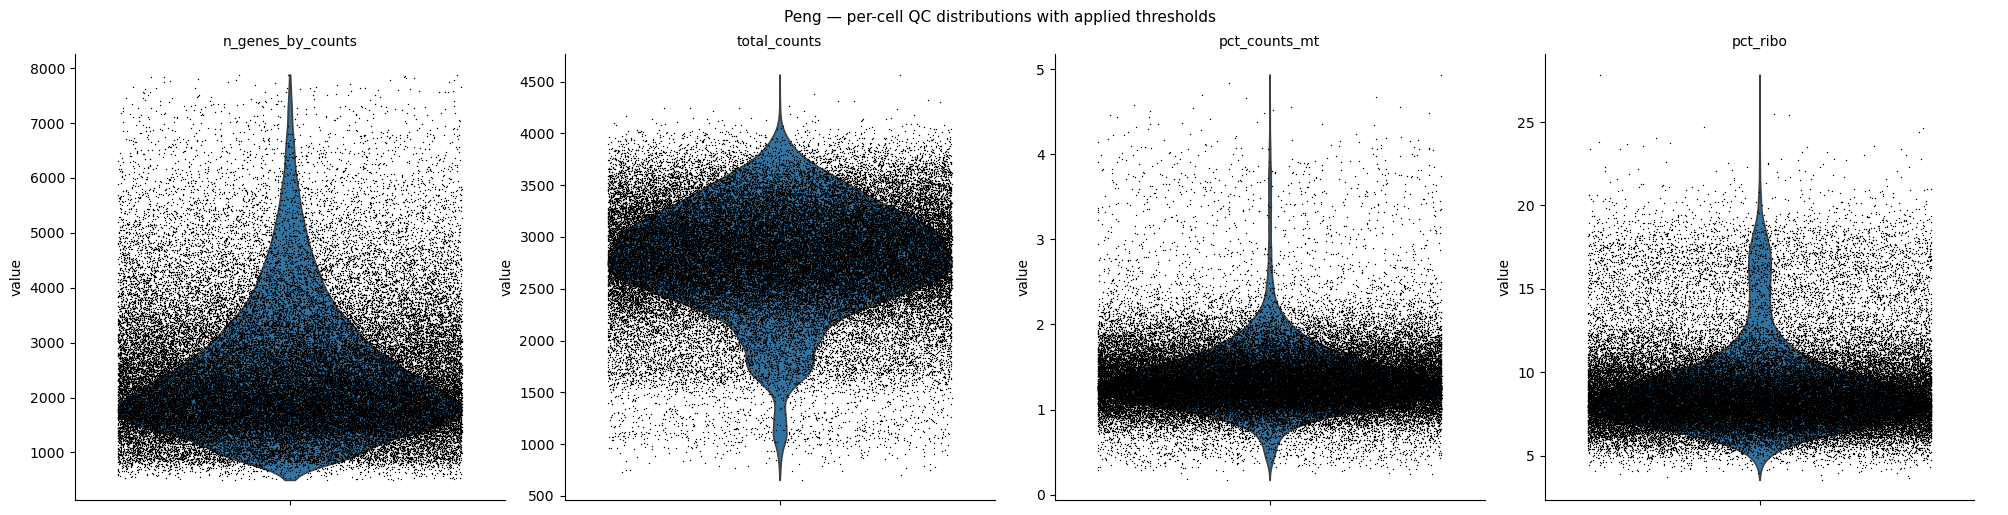


PER-CELL QC (Peng)

  criterion                        cells       pct
  genes < 200                          0     0.00%
  genes > 7000                       198     0.34%
  pct_mt > 20.0                        0     0.00%
  pct_ribo > 15.0                  3,251     5.66%   <- REPORTED ONLY, not applied

  failing at least one applied criterion: 198 (0.34%)


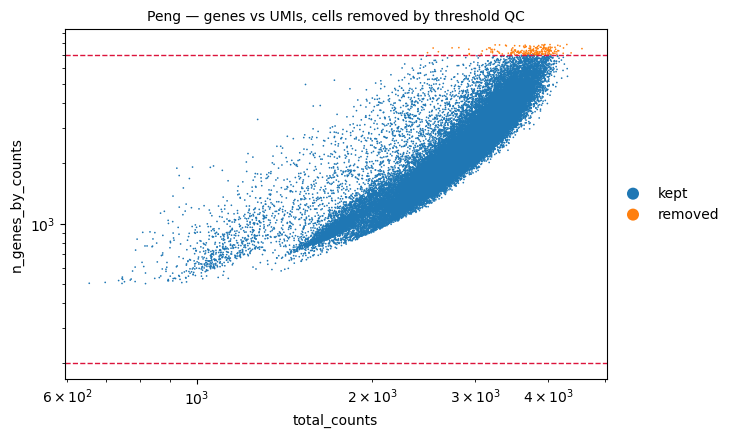


SCRUBLET -- fitted per patient (Peng)

  patient         n_cells   doublets     rate
  T2                3,036          0     0.0%
  T4                1,023          0     0.0%
  T5                1,110          0     0.0%
  T6                1,860          0     0.0%
  T7                  737          0     0.0%
  T8                  684          0     0.0%
  T9                2,339          0     0.0%
  T10                 827          0     0.0%
  T11               3,139          0     0.0%
  T12               2,266          0     0.0%
  T13               2,050          0     0.0%
  T15               1,943          0     0.0%
  T16               1,615          0     0.0%
  T17               2,065          0     0.0%
  T19               2,915          0     0.0%
  T21                 798          0     0.0%
  T23               2,856          0     0.0%
  T24               1,811          0     0.0%
  Healthy1          2,823          0     0.0%
  Healthy2          1,956          0    

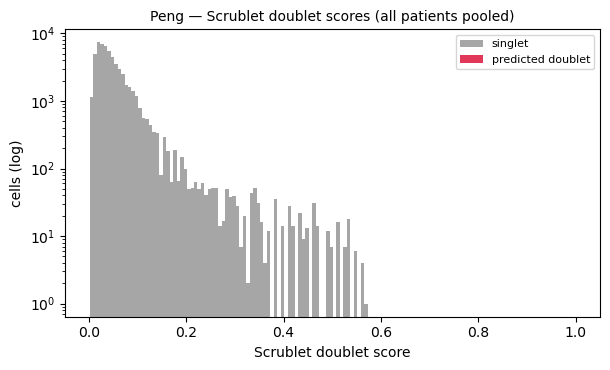

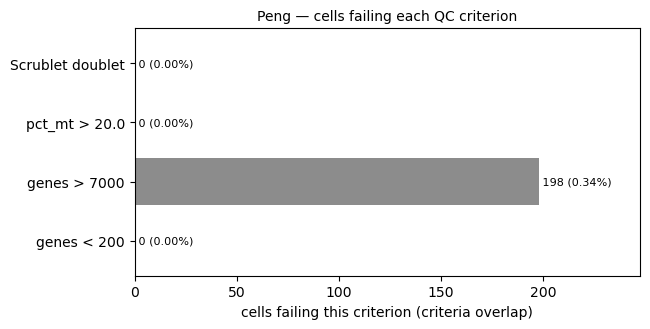


CELLS: 57,443 loaded -> 57,245 after thresholds -> 57,245 after doublet removal (198 removed, 0.34%)
RAM in use: 2.4 GB

  reusing the existing PCA basis; rebuilding the neighbour graph

LEIDEN RESOLUTION SWEEP (agreement between adjacent resolutions)

  resolution 0.5   -> 23 clusters
  resolution 0.8   -> 32 clusters
  resolution 1.0   -> 36 clusters
  resolution 1.5   -> 44 clusters

  pair                 ARI     NMI
  0.5 -> 0.8         0.922   0.943
  0.8 -> 1.0         0.842   0.942
  1.0 -> 1.5         0.776   0.920

  using resolution 1.0 throughout

malignant cells: 11,280 | patients: 29
patients with >= 50 cells: 24

basal coverage WITHOUT CTSL2->CTSV: 22/25
basal coverage WITH    CTSL2->CTSV: 23/25   <- gene recovered

classical vs basal (Spearman): -0.451
wrote peng_malignant_aim2.h5ad
RAM in use: 3.0 GB


In [8]:
# ==========================================================================
# 3 · PENG PREPROCESSING (conditional)
# per-cell QC (before clustering) -> per-patient doublet screen -> Leiden resolution sweep
# (QC evidence only; malignant identity comes from the TISCH annotation) -> Moffitt
# classical/basal scoring -> write peng_malignant_aim2.h5ad. Figures: QC distributions,
# genes-vs-UMIs, Scrublet histogram, per-criterion removal bars.
# ==========================================================================

if not need_build(PENG_MAL):
    print("peng_malignant_aim2.h5ad exists -- skipping Peng preprocessing")
else:
    from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

    # NOT backed='r': calculate_qc_metrics, leiden and boolean .copy() subsetting
    # all silently misbehave on a backed object. Load once, downcast to float32.
    peng = sc.read_h5ad(PENG_PROC)
    if peng.X.dtype != np.float32:
        peng.X = peng.X.astype(np.float32)
    peng = add_qc(peng)
    print("loaded: {:,} cells | {:,} genes | {} patients | {}".format(
        peng.n_obs, peng.n_vars, peng.obs["Patient"].nunique(), mem()))

    peng.obs["pct_ribo"] = pct_ribo(peng)

    # ---- 1. per-cell QC ----------------------------------------------------
    # Each criterion is evaluated and reported independently, so a reader can see
    # which one is doing the work. They overlap, so the counts do not sum.
    fail = {
        "genes < {}".format(QC_MIN_GENES):
            (peng.obs["n_genes_by_counts"] < QC_MIN_GENES).values,
        "genes > {}".format(QC_MAX_GENES):
            (peng.obs["n_genes_by_counts"] > QC_MAX_GENES).values,
        "pct_mt > {}".format(QC_MAX_PCT_MT):
            (peng.obs["pct_counts_mt"] > QC_MAX_PCT_MT).values,
    }
    fig_qc_distributions(peng, "Peng — per-cell QC distributions with applied thresholds",
                         "peng")

    n0 = peng.n_obs
    print("\nPER-CELL QC (Peng)\n")
    print("  {:<28}{:>10}{:>10}".format("criterion", "cells", "pct"))
    for k, v in fail.items():
        print("  {:<28}{:>10,}{:>9.2f}%".format(k, int(v.sum()), 100.0 * v.mean()))
    ribo_would = (peng.obs["pct_ribo"] > RIBO_REPORT_CUT).values
    print("  {:<28}{:>10,}{:>9.2f}%   <- REPORTED ONLY, not applied".format(
        "pct_ribo > {} ".format(RIBO_REPORT_CUT), int(ribo_would.sum()),
        100.0 * ribo_would.mean()))

    keep_thresh = ~np.any(np.column_stack(list(fail.values())), axis=1)
    print("\n  failing at least one applied criterion: {:,} ({:.2f}%)".format(
        int((~keep_thresh).sum()), 100.0 * (~keep_thresh).mean()))
    fig_genes_vs_umis(peng, keep_thresh,
                      "Peng — genes vs UMIs, cells removed by threshold QC", "peng")

    # ---- 2. doublets, fitted per patient -----------------------------------
    # Scored on row indices of the un-subset object so that both masks can be
    # applied in ONE copy. Two sequential .copy() calls put RAM over 5 GB.
    d_score, d_call, d_ran = scrublet_per_patient(peng, restrict=keep_thresh, label="Peng")
    if d_ran:
        fig_scrublet(d_score, d_call, "Peng — Scrublet doublet scores (all patients pooled)",
                     "peng")
        fail["Scrublet doublet"] = d_call
    fig_removal_bars({k: int(v.sum()) for k, v in fail.items()}, n0,
                     "Peng — cells failing each QC criterion", "peng")

    peng = peng[keep_thresh & ~d_call].copy()
    free()
    print("\nCELLS: {:,} loaded -> {:,} after thresholds -> {:,} after doublet removal "
          "({:,} removed, {:.2f}%)".format(
              n0, int(keep_thresh.sum()), peng.n_obs, n0 - peng.n_obs,
              100.0 * (n0 - peng.n_obs) / n0))
    print(mem())

    # ---- 3. clustering, on the cleaned cells -------------------------------
    # The neighbour graph shipped with the object was built on the full cell set and
    # is stale now. Drop it and rebuild. The PCA basis is reused where present:
    # removing a fraction of a percent of cells does not move the principal
    # components, and reusing it keeps this run comparable to the earlier one.
    for k in ("connectivities", "distances"):
        if k in peng.obsp:
            del peng.obsp[k]
    if "X_pca" not in peng.obsm:
        print("\n  no PCA on the object -- computing ({} comps)".format(N_PCS))
        sc.pp.pca(peng, n_comps=N_PCS, random_state=SEED)
    else:
        print("\n  reusing the existing PCA basis; rebuilding the neighbour graph")
    sc.pp.neighbors(peng, n_neighbors=15, random_state=SEED)

    print("\nLEIDEN RESOLUTION SWEEP (agreement between adjacent resolutions)\n")
    RES = [0.5, 0.8, 1.0, 1.5]
    labels = {}
    for r in RES:
        k = "leiden_{}".format(r)
        sc.tl.leiden(peng, resolution=r, key_added=k, random_state=SEED)
        labels[r] = peng.obs[k].values
        print("  resolution {:<5} -> {} clusters".format(r, peng.obs[k].nunique()))
    print("\n  {:<16}{:>8}{:>8}".format("pair", "ARI", "NMI"))
    for a, b in zip(RES[:-1], RES[1:]):
        print("  {:<16}{:>8.3f}{:>8.3f}".format(
            "{} -> {}".format(a, b),
            adjusted_rand_score(labels[a], labels[b]),
            normalized_mutual_info_score(labels[a], labels[b])))
    print("\n  using resolution {} throughout".format(LEIDEN_RES))
    peng.obs["leiden"] = peng.obs["leiden_{}".format(LEIDEN_RES)].values
    peng.obs = peng.obs.drop(columns=["leiden_{}".format(r) for r in RES])

    # The malignant compartment comes from the TISCH annotation, not from these
    # clusters, so cluster renumbering does not propagate. Only the cell set does.

    # ---- 4. malignant + Moffitt --------------------------------------------
    mal = add_qc(peng[peng.obs[MAL_COL] == "Malignant cells"].copy())
    raw_p = set(mal.raw.var_names)
    print("\nmalignant cells: {:,} | patients: {}".format(
        mal.n_obs, mal.obs["Patient"].nunique()))
    pp = mal.obs["Patient"].value_counts()
    print("patients with >= {} cells: {}".format(MIN_CELLS, int((pp >= MIN_CELLS).sum())))

    print("\nbasal coverage WITHOUT CTSL2->CTSV: {}/25".format(
        len([g for g in MOFFITT_BASAL_RAW if g in raw_p])))
    print("basal coverage WITH    CTSL2->CTSV: {}/25   <- gene recovered".format(
        len([g for g in MOFFITT_BASAL if g in raw_p])))

    score(mal, MOFFITT_CLASSICAL, "classical_score")
    score(mal, MOFFITT_BASAL, "basal_score")
    print("\nclassical vs basal (Spearman): {:+.3f}".format(
        spearmanr(mal.obs["classical_score"], mal.obs["basal_score"])[0]))

    mal.write_h5ad(PENG_MAL)
    print("wrote", os.path.basename(PENG_MAL))
    free(peng, mal)
    print(mem())


## 4 · Steele preprocessing — per-cell QC, doublet screen, Harmony, compartments, Moffitt

*Methods → Single-Cell Preprocessing; Malignant Compartment and the Subtype Scoring.*
**Conditional** — rebuilt only if `steele_malignant_scored.h5ad` is absent.

Steele arrives QC'd and already log-normalised (library-size normalisation to 10,000 counts
per cell followed by `log1p`, upstream), so `normalize_total` / `log1p` are **not** re-run —
doing so would normalise twice. The same per-cell QC thresholds as Peng are re-applied here
in visible code; where the upstream filter already applied them these lines remove nothing,
and that is itself the evidence.

**Harmony is load-bearing here in a way it is not for Peng.** Steele has no supplied
cell-type annotation, so its malignant compartment is **defined by these clusters**: each
cell is scored for the seven compartment marker sets, each Leiden cluster is assigned to the
compartment with the highest mean score, and the `ductal_malignant` clusters become the
malignant set. Without batch correction, cells cluster by patient rather than by cell type
and the compartment assignment would be wrong — so the before/after Harmony UMAP is drawn as
the check, and a Harmony failure aborts to an explicit warning rather than silently using
uncorrected PCA.

loaded: 41,415 cells | 25,730 genes | 16 patients


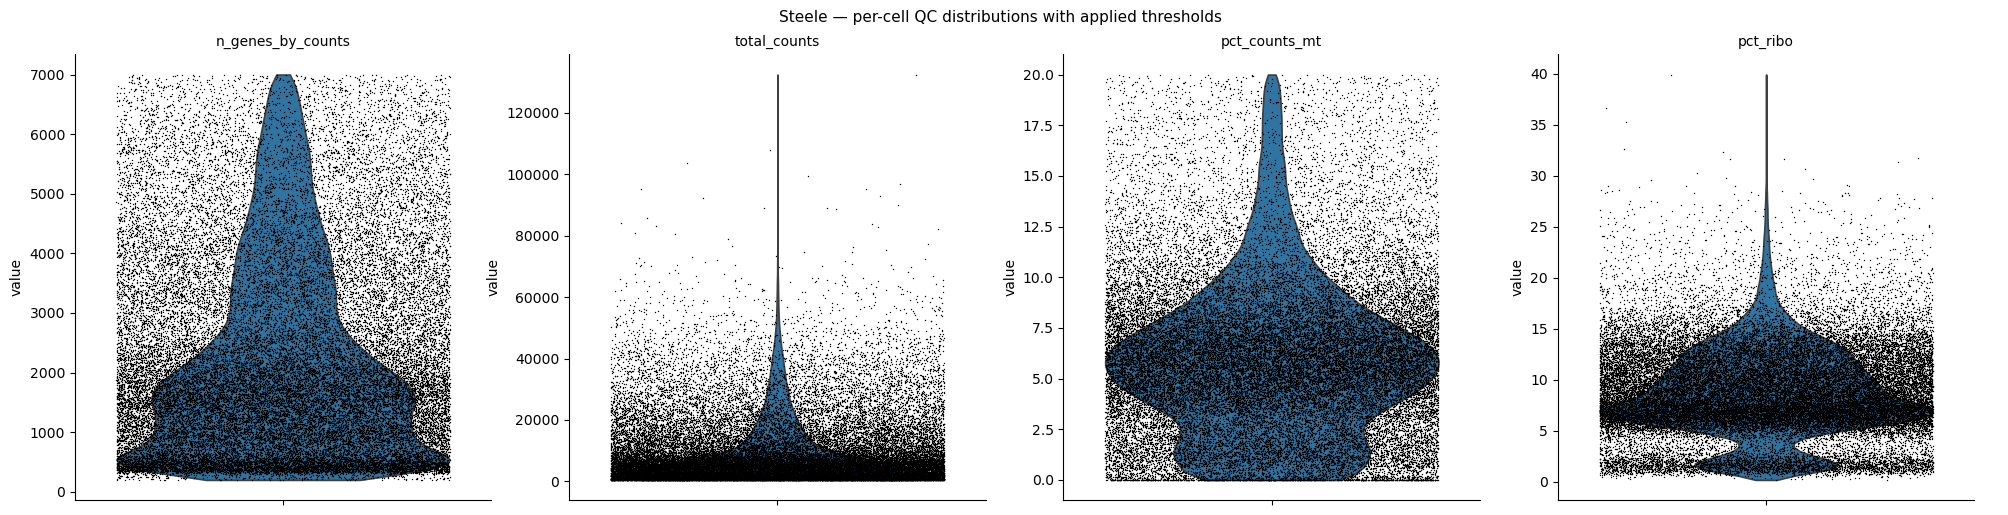


PER-CELL QC (Steele)

  criterion                        cells       pct
  genes < 200                          0     0.00%
  genes > 7000                         0     0.00%
  pct_mt > 20.0                        0     0.00%
  pct_ribo > 15.0                  3,041     7.34%   <- REPORTED ONLY, not applied

  (zeros mean the upstream filter had already applied these thresholds)


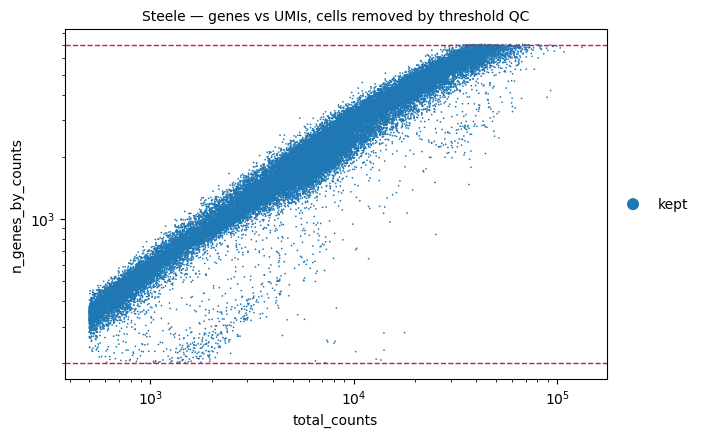


SCRUBLET -- fitted per patient (Steele)

  patient         n_cells   doublets     rate
  TISSUE_1          1,043          0     0.0%
  TISSUE_2          1,735          0     0.0%
  TISSUE_3          1,888          0     0.0%
  TISSUE_4          1,849          0     0.0%
  TISSUE_5          1,295          0     0.0%
  TISSUE_6          1,921          0     0.0%
  TISSUE_7          7,160          0     0.0%
  TISSUE_8          4,268          0     0.0%
  TISSUE_9          4,045          0     0.0%
  TISSUE_10         1,211          0     0.0%
  TISSUE_11         4,520          0     0.0%
  TISSUE_12         1,461          0     0.0%
  TISSUE_13         4,840          0     0.0%
  TISSUE_14           660          0     0.0%
  TISSUE_15         2,600          0     0.0%
  TISSUE_16           919          0     0.0%


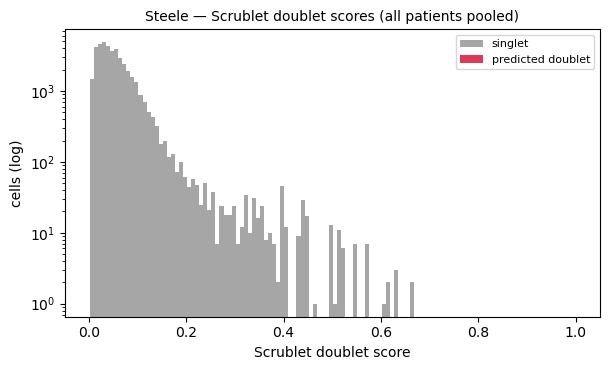

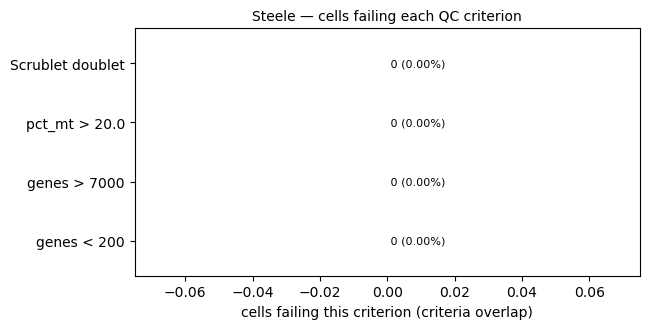


CELLS: 41,415 loaded -> 41,415 after thresholds -> 41,415 after doublet removal (0 removed, 0.00%)
RAM in use: 2.0 GB

HVGs: 2000 (recomputed on the QC'd cells)


2026-08-22 21:46:55,381 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-22 21:46:58,482 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-22 21:46:58,677 - harmonypy - INFO - Iteration 1 of 10
2026-08-22 21:47:10,339 - harmonypy - INFO - Iteration 2 of 10
2026-08-22 21:47:22,091 - harmonypy - INFO - Iteration 3 of 10
2026-08-22 21:47:34,031 - harmonypy - INFO - Iteration 4 of 10
2026-08-22 21:47:45,999 - harmonypy - INFO - Iteration 5 of 10
2026-08-22 21:47:57,615 - harmonypy - INFO - Iteration 6 of 10
2026-08-22 21:48:09,472 - harmonypy - INFO - Iteration 7 of 10
2026-08-22 21:48:21,408 - harmonypy - INFO - Iteration 8 of 10
2026-08-22 21:48:31,239 - harmonypy - INFO - Iteration 9 of 10
2026-08-22 21:48:36,184 - harmonypy - INFO - Converged after 9 iterations


Harmony: converged


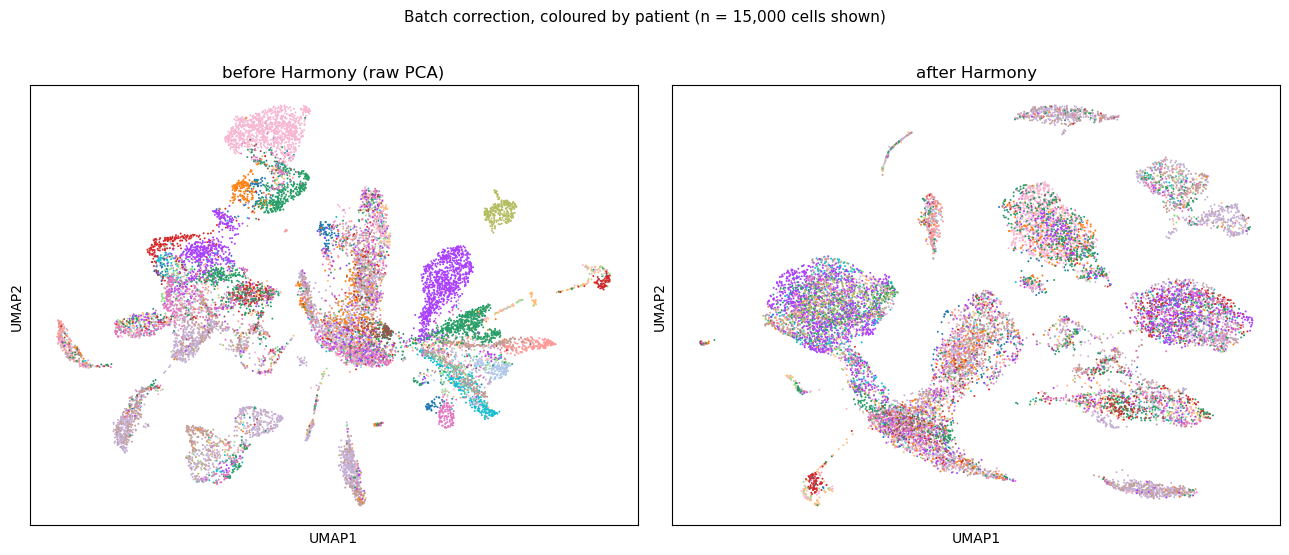

Leiden clusters: 26

cluster -> compartment:
leiden
0     ductal_malignant
1              myeloid
2              myeloid
3                Tcell
4                Tcell
5                Tcell
6                Tcell
7              myeloid
8          endothelial
9           fibroblast
10               Bcell
11             myeloid
12    ductal_malignant
13    ductal_malignant
14               Bcell
15          fibroblast
16             myeloid
17    ductal_malignant
18             myeloid
19              acinar
20             myeloid
21             myeloid
22         endothelial
23    ductal_malignant
24         endothelial
25               Bcell

cells per compartment:
compartment
myeloid             14410
Tcell               10375
ductal_malignant     9353
Bcell                2395
fibroblast           2394
endothelial          1956
acinar                532

classical vs basal (Spearman): -0.034
  (expect WEAK -- Steele's subtype axis is compressed relative to Peng)

malignant cells: 9,3

In [9]:
# ==========================================================================
# 4 · STEELE PREPROCESSING (conditional)
# Same per-cell QC as Peng -> per-patient doublet screen -> HVG/scale/PCA -> Harmony (batch
# correction on Patient; load-bearing, because Steele's malignant compartment is DEFINED by
# these clusters) -> Leiden -> compartment labelling by marker scoring -> Moffitt scoring on
# the ductal_malignant cells -> write steele_malignant_scored.h5ad. The before/after Harmony
# UMAP is the check; a Harmony failure aborts to a warning rather than using uncorrected PCA.
# ==========================================================================

if not need_build(STEELE_MAL):
    print("steele_malignant_scored.h5ad exists -- skipping Steele preprocessing")
else:
    st = add_qc(sc.read_h5ad(STEELE_QC))
    print("loaded: {:,} cells | {:,} genes | {} patients".format(
        st.n_obs, st.n_vars, st.obs["Patient"].nunique()))
    if st.raw is None:
        st.raw = st
    st.obs["pct_ribo"] = pct_ribo(st)

    # ---- 1. per-cell QC, identical thresholds to Peng ----------------------
    fail = {
        "genes < {}".format(QC_MIN_GENES):
            (st.obs["n_genes_by_counts"] < QC_MIN_GENES).values,
        "genes > {}".format(QC_MAX_GENES):
            (st.obs["n_genes_by_counts"] > QC_MAX_GENES).values,
        "pct_mt > {}".format(QC_MAX_PCT_MT):
            (st.obs["pct_counts_mt"] > QC_MAX_PCT_MT).values,
    }
    fig_qc_distributions(st, "Steele — per-cell QC distributions with applied thresholds",
                         "steele")

    n0 = st.n_obs
    print("\nPER-CELL QC (Steele)\n")
    print("  {:<28}{:>10}{:>10}".format("criterion", "cells", "pct"))
    for k, v in fail.items():
        print("  {:<28}{:>10,}{:>9.2f}%".format(k, int(v.sum()), 100.0 * v.mean()))
    ribo_would = (st.obs["pct_ribo"] > RIBO_REPORT_CUT).values
    print("  {:<28}{:>10,}{:>9.2f}%   <- REPORTED ONLY, not applied".format(
        "pct_ribo > {} ".format(RIBO_REPORT_CUT), int(ribo_would.sum()),
        100.0 * ribo_would.mean()))
    print("\n  (zeros mean the upstream filter had already applied these thresholds)")

    keep_thresh = ~np.any(np.column_stack(list(fail.values())), axis=1)
    fig_genes_vs_umis(st, keep_thresh,
                      "Steele — genes vs UMIs, cells removed by threshold QC", "steele")

    # ---- 2. doublets, fitted per patient -----------------------------------
    d_score, d_call, d_ran = scrublet_per_patient(st, restrict=keep_thresh, label="Steele")
    if d_ran:
        fig_scrublet(d_score, d_call, "Steele — Scrublet doublet scores (all patients pooled)",
                     "steele")
        fail["Scrublet doublet"] = d_call
    fig_removal_bars({k: int(v.sum()) for k, v in fail.items()}, n0,
                     "Steele — cells failing each QC criterion", "steele")

    st = st[keep_thresh & ~d_call].copy()
    free()
    print("\nCELLS: {:,} loaded -> {:,} after thresholds -> {:,} after doublet removal "
          "({:,} removed, {:.2f}%)".format(
              n0, int(keep_thresh.sum()), st.n_obs, n0 - st.n_obs,
              100.0 * (n0 - st.n_obs) / n0))
    print(mem())

    # ---- 3. HVG / PCA / Harmony / Leiden -----------------------------------
    # HVGs are recomputed rather than reused: the cell set changed, and which genes
    # are variable is a property of the cells.
    sc.pp.highly_variable_genes(st, n_top_genes=2000, flavor="seurat")
    print("\nHVGs: {} (recomputed on the QC'd cells)".format(int(st.var.highly_variable.sum())))

    hv = st[:, st.var.highly_variable].copy()
    sc.pp.scale(hv, max_value=10)
    sc.tl.pca(hv, n_comps=N_PCS, random_state=SEED)

    try:
        sc.external.pp.harmony_integrate(hv, "Patient", random_state=SEED)
        rep = "X_pca_harmony"
        print("Harmony: converged")
    except Exception as e:
        rep = "X_pca"
        print("\n" + "!" * 66)
        print("HARMONY FAILED: {}".format(e))
        print("Falling back to UNCORRECTED PCA -- compartments will be WRONG.")
        print("Fix:  pip install harmonypy   then re-run.")
        print("!" * 66 + "\n")

    fig_harmony_before_after(hv, patient_key="Patient", tag="steele")

    sc.pp.neighbors(hv, n_neighbors=15, use_rep=rep, random_state=SEED)
    sc.tl.leiden(hv, resolution=LEIDEN_RES, key_added="leiden", random_state=SEED)
    st.obs["leiden"] = hv.obs["leiden"].values
    print("Leiden clusters: {}".format(st.obs["leiden"].nunique()))

    for ct, gl in COMPARTMENT_MARKERS.items():
        score(st, gl, "score_" + ct)
    cols = ["score_" + ct for ct in COMPARTMENT_MARKERS]
    assign = (st.obs.groupby("leiden", observed=True)[cols].mean()
              .idxmax(axis=1).str.replace("score_", "", regex=False))
    st.obs["compartment"] = st.obs["leiden"].map(assign).astype(str)

    print("\ncluster -> compartment:")
    print(assign.to_string())
    print("\ncells per compartment:")
    print(st.obs["compartment"].value_counts().to_string())

    st_mal = add_qc(st[st.obs["compartment"] == "ductal_malignant"].copy())
    score(st_mal, MOFFITT_CLASSICAL, "classical_score")
    score(st_mal, MOFFITT_BASAL, "basal_score")
    print("\nclassical vs basal (Spearman): {:+.3f}".format(
        spearmanr(st_mal.obs["classical_score"], st_mal.obs["basal_score"])[0]))
    print("  (expect WEAK -- Steele's subtype axis is compressed relative to Peng)")

    pp = st_mal.obs["Patient"].value_counts()
    print("\nmalignant cells: {:,} | patients: {} | patients with >= {} cells: {}".format(
        st_mal.n_obs, st_mal.obs["Patient"].nunique(), MIN_CELLS,
        int((pp >= MIN_CELLS).sum())))

    st_mal.write_h5ad(STEELE_MAL)
    print("\nwrote", os.path.basename(STEELE_MAL))
    free(st, hv, st_mal)
    print(mem())


## 5 · cNMF transcriptional programs — variance normalisation and K selection

*Methods → Transcriptional Programs and Copy-Number Inference.*
**Conditional** — rebuilt only if `peng_cnmf_K10_varnorm.npz` is absent.

Consensus non-negative matrix factorisation (**cNMF**) decomposes the Peng malignant
compartment into transcriptional programs **without** using subtype labels — this is a
faithful reimplementation (iterated NMF followed by consensus KMeans clustering of the
L2-normalised spectra) applied to the log-normalised HVG matrix rather than to linearly
normalised counts. Two decisions are **evidenced rather than asserted**:

**(a) Variance normalisation.** Each gene is divided by its standard deviation *without*
centering (centering introduces negative values and breaks NMF's non-negativity constraint).
The K-sweep is run **twice** — before and after — so the housekeeping (ribosomal / MT) factor
that dominates the un-normalised decomposition is *shown* to disappear, not merely claimed to.

**(b) K = 10**, at the stability peak, where stability is the mean silhouette width of the
pooled program spectra across 10 random restarts. Because only 10 restarts are used, a
rebuild is Spearman-correlated against the retained programs and required to exceed 0.95
before any downstream use — the positive controls and program scores depend on these programs.

In [10]:
# ==========================================================================
# 5 · cNMF TRANSCRIPTIONAL PROGRAMS (conditional)
# Consensus NMF reimplementation on the 2,000 HVGs of the Peng malignant compartment,
# subtype-label-free. The K-sweep is run TWICE -- raw vs variance-normalised -- so the
# ribosomal/MT housekeeping factor is SHOWN to vanish under variance normalisation.
# Stability = silhouette of the pooled L2-normalised spectra over 10 restarts; peaks at
# K=10. A rebuild is correlated against the retained programs and must exceed 0.95, because
# the positive controls and program scores depend on the exact programs.
# ==========================================================================

if not need_build(PENG_CNMF):
    print("peng_cnmf_K10_varnorm.npz exists -- skipping cNMF")
else:
    from sklearn.decomposition import NMF
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score
    from sklearn.preprocessing import normalize
    os.environ["OMP_NUM_THREADS"] = "1"

    import anndata as ad_mod
    gc.collect()
    print(mem())

    # MEMORY-LEAN: .raw.to_adata() copies obs/var/obsm and then scanpy copies the
    # sparse matrix again inside highly_variable_genes. On a 21k-gene raw matrix that
    # is enough to OOM. Build a minimal AnnData holding only X and gene names.
    _m = sc.read_h5ad(PENG_MAL)
    _X = _m.raw.X
    _genes = list(_m.raw.var_names)
    free(_m)

    tmp = ad_mod.AnnData(X=_X, var=pd.DataFrame(index=_genes))
    free(_X)
    print("raw matrix: {} cells x {} genes | {}".format(tmp.n_obs, tmp.n_vars, mem()))

    sc.pp.highly_variable_genes(tmp, n_top_genes=2000, flavor="seurat")
    hvg = tmp.var_names[tmp.var.highly_variable].tolist()

    X = tmp[:, hvg].X
    X = np.asarray(X.todense()) if hasattr(X, "todense") else np.asarray(X)
    X = np.clip(X, 0, None).astype(np.float32)
    free(tmp)
    print("NMF input: {} cells x {} HVGs | {}\n".format(X.shape[0], X.shape[1], mem()))

    def sweep(mat, Ks=(6, 8, 10, 12), n_reps=10):
        store, rows = {}, []
        for K in Ks:
            t = time.time()
            spectra = []
            for rep in range(n_reps):
                m = NMF(n_components=K, init="random", random_state=rep,
                        max_iter=500, solver="cd", beta_loss="frobenius").fit(mat)
                spectra.append(normalize(m.components_, norm="l2", axis=1))
            spectra = np.vstack(spectra)
            km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(spectra)
            store[K] = km.cluster_centers_
            rows.append({"K": K,
                         "stability": round(float(silhouette_score(spectra, km.labels_)), 3),
                         "sec": round(time.time() - t, 1)})
            print("   ", rows[-1])
        return store, pd.DataFrame(rows)

    print("SWEEP 1 -- raw HVG matrix (NO variance normalisation)")
    store_raw, tab_raw = sweep(X)
    print("\n  Top 12 genes of each K=8 program (NO variance normalisation):")
    for i, prog in enumerate(store_raw[8]):
        print("    P{}: {}".format(i + 1, ", ".join(hvg[j] for j in np.argsort(prog)[::-1][:12])))
    print("    -> a program dominated by RPS*/RPL*/MT- genes is the housekeeping artifact:")
    print("       magnitude, not biology.\n")

    gstd = X.std(axis=0); gstd[gstd == 0] = 1.0
    Xv = (X / gstd).astype(np.float32)
    print("SWEEP 2 -- variance-normalised")
    store_vn, tab_vn = sweep(Xv)
    print("\n  Top 12 genes of each K=8 program (WITH variance normalisation):")
    for i, prog in enumerate(store_vn[8]):
        print("    P{}: {}".format(i + 1, ", ".join(hvg[j] for j in np.argsort(prog)[::-1][:12])))
    print("    -> the housekeeping program should be gone.\n")

    comp = tab_raw[["K", "stability"]].merge(tab_vn[["K", "stability"]], on="K",
                                             suffixes=("_raw", "_varnorm"))
    print("STABILITY BY K\n")
    print(comp.to_string(index=False))
    print("\nstability peaks at K = {}".format(int(tab_vn.loc[tab_vn["stability"].idxmax(), "K"])))

    print("\nK=10 PROGRAMS (variance-normalised), top 15 genes each\n")
    for i, prog in enumerate(store_vn[CNMF_K]):
        label = PROG_NAMES[i] if i < len(PROG_NAMES) else "program_{}".format(i + 1)
        print("  [{}]  {}".format(label, ", ".join(hvg[j] for j in np.argsort(prog)[::-1][:15])))

    # ---- guard: a rebuild must not silently change the programs -------------
    if os.path.exists(PENG_CNMF):
        old = np.load(PENG_CNMF, allow_pickle=True)
        old_p, old_g = old["programs"], list(old["genes"])
        if old_g == hvg:
            print("\nREBUILT vs EXISTING programs (correlation of loadings)\n")
            worst = 1.0
            for i, name in enumerate(PROG_NAMES):
                r = spearmanr(old_p[i], store_vn[CNMF_K][i])[0]
                worst = min(worst, r)
                print("  {:<14}{:>8.3f}{}".format(
                    name, r, "" if r > 0.95 else "   <-- CHANGED"))
            if worst > 0.95:
                print("\n  programs reproduce -- downstream numbers unaffected")
            else:
                print("\n  *** PROGRAMS CHANGED ***")
                print("  The positive controls and program scores depend on these.")
                print("  Re-run the whole notebook and use the numbers throughout.")
        else:
            print("\n  HVG set differs from the existing .npz -- programs are not comparable")

    np.savez(PENG_CNMF, genes=np.array(hvg), programs=store_vn[CNMF_K])
    print("\nwrote", os.path.basename(PENG_CNMF))
    free(X, Xv, store_raw, store_vn)
    print(mem())

RAM in use: 4.1 GB
raw matrix: 11280 cells x 21066 genes | RAM in use: 4.5 GB
NMF input: 11280 cells x 2000 HVGs | RAM in use: 4.6 GB

SWEEP 1 -- raw HVG matrix (NO variance normalisation)
    {'K': 6, 'stability': 0.816, 'sec': 51.7}
    {'K': 8, 'stability': 0.993, 'sec': 69.9}
    {'K': 10, 'stability': 0.816, 'sec': 59.6}
    {'K': 12, 'stability': 0.878, 'sec': 74.4}

  Top 12 genes of each K=8 program (NO variance normalisation):
    P1: FXYD3, MALAT1, RPS16, SPINK1, TFF1, ZFP36, S100A6, B2M, REG4, LGALS4, TFF2, FXYD5
    P2: SPINK1, FTH1, MALAT1, SERPINA1, MMP7, B2M, CD74, S100A6, FTL, KRT19, MT2A, MT1X
    P3: MALAT1, MT2A, LGALS1, IGFBP7, B2M, S100A6, GAPDH, VIM, FTH1, INS, RPS16, S100A4
    P4: MALAT1, FTL, S100A6, FTH1, B2M, GAPDH, HLA-B, RPS16, CSTB, CD74, NEAT1, LYZ
    P5: INS, SPINK1, MALAT1, OLFM4, LYZ, CD74, S100A6, B2M, REG1A, HLA-B, MMP7, IFI27
    P6: S100A6, MALAT1, B2M, TFF1, CEACAM6, FTH1, C15orf48, KRT13, SPINK1, KRT19, LCN2, CTSE
    P7: MALAT1, B2M, FTH1, S100

## 6 · inferCNV — confirming the malignant compartment is aneuploid  ·  **Fig. 1**

*Methods → Transcriptional Programs and Copy-Number Inference; Results → Cell Populations.*
**Conditional** — rebuilt only if `peng_infercnv_v2.h5ad` (Peng) / `steele_infercnv.h5ad`
(Steele) is absent.

Marker-based malignant calling can admit normal ductal cells, which would distort the
signature scores. inferCNV infers copy number from expression: true malignant cells are
**aneuploid**, normal cells **diploid**. Immune and stromal cells form the **diploid
reference**; a malignant cell above the reference's **95th-percentile** CNV score is called
CNV-confirmed aneuploid.

**Run on the full transcriptome (~21k genes), not an HVG subset** — an HVG-restricted run is
gene-starved per chromosome and yields a false null. The malignant-to-reference **ratio** and
the fraction above threshold are the primary evidence (manuscript **Fig. 1b/1d**); this
section is run for **both** cohorts so the Methods claim of copy-number confirmation applies
to each. For Steele, the immune/stromal reference is labelled by the same marker sets that
labelled the malignant cells, so the copy-number result **corroborates** the marker-based
assignment rather than being a fully independent check.

subsample: 8,000 cells x 21,066 genes (full transcriptome) | RAM in use: 4.9 GB
genes with chromosomal positions: 17,376/21,066


  0%|          | 0/2 [00:00<?, ?it/s]


CNV SCORE BY COMPARTMENT

                           mean    median  size
Celltype (malignancy)                          
Immune cells           0.003660  0.003392  2000
Malignant cells        0.011196  0.009091  4000
Stromal cells          0.004437  0.004661  2000

malignant / reference CNV ratio: 2.77x  -> CONFIRMED aneuploid
CNV-confirmed aneuploid: 3,362/4,000 (84.0%)
fraction below the diploid 95th pctile: 16.0%
  (an UPPER BOUND on normal-cell contamination -- some malignant PDAC
   cells are genuinely near-diploid, so this over-counts)


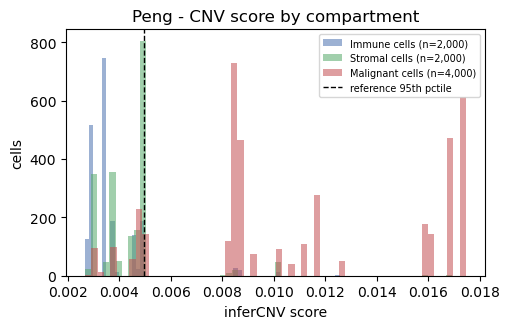


wrote peng_infercnv_v2.h5ad
RAM in use: 5.0 GB


In [11]:
# ==========================================================================
# 6 · inferCNV -- PENG (conditional)   ·   Fig. 1a/1b
# Reads ONLY the sampled rows straight from the file (h5py + sparse_dataset) so the section
# is independent of how much memory earlier sections left held. Full transcriptome, NOT an
# HVG subset (an HVG run is gene-starved per chromosome and gives a false null). Immune +
# stromal cells are the diploid reference; malignant cells above the reference 95th
# percentile are CNV-confirmed aneuploid. The ratio and the fraction above threshold are the
# primary evidence for Fig. 1.
# ==========================================================================

if not need_build(PENG_CNV):
    print("peng_infercnv_v2.h5ad exists -- skipping inferCNV")
else:
    import infercnvpy as cnv
    from pybiomart import Server
    import anndata as ad_mod

    import h5py
    try:
        from anndata.io import read_elem, sparse_dataset
    except ImportError:
        from anndata.experimental import read_elem, sparse_dataset

    # Read ONLY the rows this section uses. sc.read_h5ad() would materialise the whole
    # object -- 142M nonzeros in /raw, 542 MiB for the index array alone -- and then
    # discard 86% of the cells. Whether that allocation succeeds depends on how much
    # memory the earlier sections left held, which makes it fail unpredictably. Pulling
    # the chosen rows straight from the file makes this section independent of what ran
    # before it.
    #
    # FULL gene set, not HVG -- an HVG-restricted run is gene-starved per chromosome
    # and yields a false null.
    _cnv_rng = np.random.default_rng(SEED)   # own stream: see the note in section 11

    with h5py.File(PENG_PROC, "r") as _f:
        _obs_all = read_elem(_f["obs"])

        def take(mask, n):
            idx = np.where(np.asarray(mask))[0]
            return _cnv_rng.choice(idx, size=min(n, len(idx)), replace=False)

        keep = np.sort(np.concatenate([
            take(_obs_all[MAL_COL] == "Immune cells", 2000),
            take(_obs_all[MAL_COL] == "Stromal cells", 2000),
            take(_obs_all[MAL_COL] == "Malignant cells", 4000)]))

        _X = sparse_dataset(_f["raw/X"])[keep]
        _var = pd.DataFrame(index=list(read_elem(_f["raw/var"]).index))
        _obs = _obs_all.iloc[keep].copy()
    free(_obs_all)
    full = ad_mod.AnnData(X=_X, obs=_obs, var=_var)
    free(_X)
    print("subsample: {:,} cells x {:,} genes (full transcriptome) | {}".format(
        full.n_obs, full.n_vars, mem()))

    ds = Server(host="http://www.ensembl.org").marts["ENSEMBL_MART_ENSEMBL"].datasets["hsapiens_gene_ensembl"]
    bm = ds.query(attributes=["external_gene_name", "chromosome_name",
                              "start_position", "end_position"])
    bm.columns = ["gene", "chromosome", "start", "end"]
    valid = [str(i) for i in range(1, 23)] + ["X", "Y"]
    bm = bm[bm["chromosome"].isin(valid)].drop_duplicates("gene").set_index("gene")

    full.var["chromosome"] = "chr" + full.var_names.map(bm["chromosome"]).astype(str)
    full.var["start"] = full.var_names.map(bm["start"])
    full.var["end"] = full.var_names.map(bm["end"])
    n_before = full.n_vars
    full = full[:, full.var["start"].notna()].copy()
    full.var["start"] = full.var["start"].astype(int)
    full.var["end"] = full.var["end"].astype(int)
    print("genes with chromosomal positions: {:,}/{:,}".format(full.n_vars, n_before))

    cnv.tl.infercnv(full, reference_key=MAL_COL,
                    reference_cat=["Immune cells", "Stromal cells"], window_size=250)
    cnv.tl.pca(full); cnv.pp.neighbors(full); cnv.tl.leiden(full); cnv.tl.cnv_score(full)

    print("\nCNV SCORE BY COMPARTMENT\n")
    print(full.obs.groupby(MAL_COL, observed=True)["cnv_score"]
          .agg(["mean", "median", "size"]).to_string())

    m_cnv = full.obs.loc[full.obs[MAL_COL] == "Malignant cells", "cnv_score"]
    r_cnv = full.obs.loc[full.obs[MAL_COL].isin(["Immune cells", "Stromal cells"]), "cnv_score"]
    ratio = m_cnv.mean() / r_cnv.mean()
    ref95 = r_cnv.quantile(0.95)
    print("\nmalignant / reference CNV ratio: {:.2f}x  -> {}".format(
        ratio, "CONFIRMED aneuploid" if ratio > 1.5 else "WEAK -- investigate"))
    print("CNV-confirmed aneuploid: {:,}/{:,} ({:.1%})".format(
        int((m_cnv > ref95).sum()), len(m_cnv), (m_cnv > ref95).mean()))
    print("fraction below the diploid 95th pctile: {:.1%}".format((m_cnv <= ref95).mean()))
    print("  (an UPPER BOUND on normal-cell contamination -- some malignant PDAC")
    print("   cells are genuinely near-diploid, so this over-counts)")

    # ---- FIGURE (additive): CNV score by compartment (Peng)  ·  Fig. 1b -----
    # Mirrors the Steele CNV figure in the next section so the two cohorts read
    # the same way. Uses only objects computed just above (full.obs, ref95).
    if FIGURES:
        _fig, _ax = plt.subplots(figsize=(5.2, 3.4))
        for _lb, _col in [("Immune cells", "#4C72B0"), ("Stromal cells", "#55A868"),
                          ("Malignant cells", "#C44E52")]:
            _v = full.obs.loc[full.obs[MAL_COL] == _lb, "cnv_score"]
            if len(_v):
                _ax.hist(_v, bins=60, alpha=0.55, color=_col,
                         label="{} (n={:,})".format(_lb, len(_v)))
        _ax.axvline(ref95, color="k", ls="--", lw=1, label="reference 95th pctile")
        _ax.set_xlabel("inferCNV score"); _ax.set_ylabel("cells")
        _ax.set_title("Peng - CNV score by compartment")
        _ax.legend(fontsize=7)
        plt.tight_layout()
        _show("peng_cnv_score")

    full.write_h5ad(PENG_CNV)
    print("\nwrote", os.path.basename(PENG_CNV))
    free(full)
    print(mem())



malignant cells from steele_malignant_scored.h5ad: 9,353
all QC'd Steele cells: 41,415 x 25,730 genes | RAM in use: 7.3 GB
  Immune cells   11/11 markers found
  Stromal cells  7/8 markers found
  Other          5/5 markers found

labels:
ref_label
Immune cells       22191
Malignant cells     9353
Stromal cells       6770
Other               3101

subsample: 8,000 cells x 17,187 genes with positions (of 25,730)


  0%|          | 0/2 [00:00<?, ?it/s]


CNV SCORE BY COMPARTMENT (Steele)

                     mean    median  size
ref_label                                
Immune cells     0.004492  0.003387  2000
Malignant cells  0.012690  0.012537  4000
Stromal cells    0.005125  0.004567  2000

malignant / reference CNV ratio: 2.64x
above reference 95th pctile:     2,650/4,000 (66.2%)
  Only 5% of reference cells clear this bar by construction, so this is
  the enrichment over a diploid baseline, not a pass rate.
  Compare against Peng's ratio and percentage printed above.


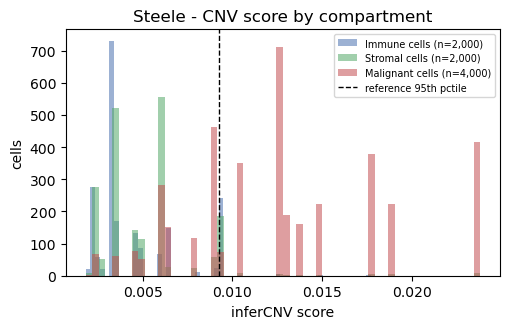


wrote steele_infercnv.h5ad
RAM in use: 2.5 GB


In [12]:
# ==========================================================================
# 6 · inferCNV -- STEELE (conditional)   ·   Fig. 1c/1d
# Mirrors the Peng block exactly (same 4,000/2,000/2,000 split, same window_size=250, same
# reference categories), so any difference in the result is a property of the cohort, not of
# the settings. Steele's reference is labelled by the SAME marker sets used for its malignant
# cells, so this corroborates the marker-based assignment rather than being fully independent.
# ==========================================================================

STEELE_CNV = os.path.join(DOWNLOADS, "steele_infercnv.h5ad")

if not need_build(STEELE_CNV):
    print("\nsteele_infercnv.h5ad exists -- skipping Steele inferCNV")
else:
    import infercnvpy as cnv
    import anndata as ad_mod

    # Malignant identity comes from the file, never re-derived. backed='r' reads obs
    # only -- the matrix is never materialised.
    mal_ids = set(sc.read_h5ad(STEELE_MAL, backed="r").obs_names)
    print("\nmalignant cells from {}: {:,}".format(
        os.path.basename(STEELE_MAL), len(mal_ids)))

    sst = sc.read_h5ad(STEELE_QC)
    if sst.raw is not None and sst.raw.n_vars >= sst.n_vars:
        sst = sst.raw.to_adata()          # full transcriptome, not the HVGs
    print("all QC'd Steele cells: {:,} x {:,} genes | {}".format(
        sst.n_obs, sst.n_vars, mem()))

    # Fold the notebook's own COMPARTMENT_MARKERS into the three-level vocabulary §6
    # uses, so the marker lists live in exactly one place. Acinar -> "Other" and is
    # excluded from the reference, matching Peng's immune-plus-stromal-only reference.
    _REF_SETS = {
        "Immune cells":  COMPARTMENT_MARKERS["Tcell"] + COMPARTMENT_MARKERS["myeloid"]
                         + COMPARTMENT_MARKERS["Bcell"],
        "Stromal cells": COMPARTMENT_MARKERS["fibroblast"]
                         + COMPARTMENT_MARKERS["endothelial"],
        "Other":         COMPARTMENT_MARKERS["acinar"],
    }
    _sc = {}
    for _name, _genes in _REF_SETS.items():
        _present = [g for g in _genes if g in sst.var_names]
        sc.tl.score_genes(sst, _present, score_name="_s", use_raw=False)
        _sc[_name] = np.asarray(sst.obs["_s"].values, dtype=float)
        print("  {:<14} {}/{} markers found".format(_name, len(_present), len(_genes)))
    del sst.obs["_s"]

    _lab = pd.DataFrame(_sc, index=sst.obs_names).idxmax(axis=1)
    _lab[sst.obs_names.isin(mal_ids)] = "Malignant cells"
    sst.obs["ref_label"] = pd.Categorical(_lab)
    print("\nlabels:")
    print(sst.obs["ref_label"].value_counts().to_string())

    _cnv_rng = np.random.default_rng(SEED)   # own stream -- see the note in §11

    def _take(mask, n):
        idx = np.where(np.asarray(mask))[0]
        return _cnv_rng.choice(idx, size=min(n, len(idx)), replace=False)

    # Same 4,000 / 2,000 / 2,000 split as Peng above.
    _keep = np.sort(np.concatenate([
        _take(sst.obs["ref_label"] == "Immune cells", 2000),
        _take(sst.obs["ref_label"] == "Stromal cells", 2000),
        _take(sst.obs["ref_label"] == "Malignant cells", 4000)]))
    sfull = sst[_keep].copy()
    free(sst)

    # bm was built for Peng earlier in this cell; re-query only if §6's Peng branch
    # was skipped, so this block works whether or not Peng rebuilt.
    try:
        bm
    except NameError:
        from pybiomart import Server
        _ds = (Server(host="http://www.ensembl.org")
               .marts["ENSEMBL_MART_ENSEMBL"].datasets["hsapiens_gene_ensembl"])
        bm = _ds.query(attributes=["external_gene_name", "chromosome_name",
                                   "start_position", "end_position"])
        bm.columns = ["gene", "chromosome", "start", "end"]
        _valid = [str(i) for i in range(1, 23)] + ["X", "Y"]
        bm = bm[bm["chromosome"].isin(_valid)].drop_duplicates("gene").set_index("gene")

    sfull.var["chromosome"] = "chr" + sfull.var_names.map(bm["chromosome"]).astype(str)
    sfull.var["start"] = sfull.var_names.map(bm["start"])
    sfull.var["end"] = sfull.var_names.map(bm["end"])
    _n_before = sfull.n_vars
    sfull = sfull[:, sfull.var["start"].notna()].copy()
    sfull.var["start"] = sfull.var["start"].astype(int)
    sfull.var["end"] = sfull.var["end"].astype(int)
    print("\nsubsample: {:,} cells x {:,} genes with positions (of {:,})".format(
        sfull.n_obs, sfull.n_vars, _n_before))

    # Identical parameters to Peng -- same window, same reference categories. Any
    # difference in the result is then a property of the cohort, not the settings.
    cnv.tl.infercnv(sfull, reference_key="ref_label",
                    reference_cat=["Immune cells", "Stromal cells"], window_size=250)
    cnv.tl.pca(sfull); cnv.pp.neighbors(sfull); cnv.tl.leiden(sfull); cnv.tl.cnv_score(sfull)

    print("\nCNV SCORE BY COMPARTMENT (Steele)\n")
    print(sfull.obs.groupby("ref_label", observed=True)["cnv_score"]
          .agg(["mean", "median", "size"]).to_string())

    _m = sfull.obs.loc[sfull.obs["ref_label"] == "Malignant cells", "cnv_score"]
    _r = sfull.obs.loc[sfull.obs["ref_label"].isin(["Immune cells", "Stromal cells"]),
                       "cnv_score"]
    _ratio = _m.mean() / _r.mean()
    _ref95 = _r.quantile(0.95)
    print("\nmalignant / reference CNV ratio: {:.2f}x".format(_ratio))
    print("above reference 95th pctile:     {:,}/{:,} ({:.1%})".format(
        int((_m > _ref95).sum()), len(_m), (_m > _ref95).mean()))
    print("  Only 5% of reference cells clear this bar by construction, so this is")
    print("  the enrichment over a diploid baseline, not a pass rate.")
    print("  Compare against Peng's ratio and percentage printed above.")

    if FIGURES:
        _, ax = plt.subplots(figsize=(5.2, 3.4))
        for _lb, _col in [("Immune cells", "#4C72B0"), ("Stromal cells", "#55A868"),
                          ("Malignant cells", "#C44E52")]:
            _v = sfull.obs.loc[sfull.obs["ref_label"] == _lb, "cnv_score"]
            if len(_v):
                ax.hist(_v, bins=60, alpha=0.55, color=_col,
                        label="{} (n={:,})".format(_lb, len(_v)))
        ax.axvline(_ref95, color="k", ls="--", lw=1, label="reference 95th pctile")
        ax.set_xlabel("inferCNV score"); ax.set_ylabel("cells")
        ax.set_title("Steele - CNV score by compartment")
        ax.legend(fontsize=7)
        plt.tight_layout()
        _show("steele_cnv_score")

    sfull.write_h5ad(STEELE_CNV)
    print("\nwrote", os.path.basename(STEELE_CNV))
    free(sfull)
    print(mem())

## 7 · Dependency signatures from DepMap  —  *Methods → Derivation of the Dependency Signature*

Dependency cannot be measured directly in single cells, so each target is represented by a
**transcriptomic proxy** derived from the cell lines where dependency *is* measured. Crucially,
a signature is derived **within the genetic context in which the vulnerability operates**, not
across the whole panel — correlating expression against dependency across all lines would mostly
recover **generic essentiality**, which is exactly the confound this study controls for.

| target | passenger gene deleted | genetic context used for derivation |
|---|---|---|
| VPS4A | VPS4B (18q, co-deleted with SMAD4) | VPS4B-low lines |
| PRMT5 | MTAP (9p21, co-deleted with CDKN2A) | MTAP-low lines |
| MAT2A | MTAP (9p21, co-deleted with CDKN2A) | MTAP-low lines |

Within the passenger-low lines (bottom expression quartile of the passenger, `LOW_Q = 0.25`,
n = 285), each gene's expression is Spearman-correlated with the target's **Chronos gene-effect
score**. Chronos is signed so **lower = more dependent**, so the genes most *negatively*
correlated with Chronos are those whose high expression tracks the strongest dependency; the
top 100 are retained as the signature.

**Two sanity gates.** The DepMap expression file leads with *metadata* columns before the gene
columns, so a naive `index_col=0` load silently yields "signatures" made of metadata names.
Gate 1 asserts the passenger genes and all three targets are present as columns in both matrices;
gate 2 asserts the **PRMT5 signature recovers PRMT5 itself** (rank 10) and that ≥ 50 signature
genes are detected in the single-cell data.

In [13]:
# ==========================================================================
# 7 · DEPENDENCY SIGNATURES FROM DEPMAP   (Methods -> Derivation of the Dependency Signature)
# DepMap loader guards against the metadata-column trap (a naive index_col=0 makes
# 'signatures' of metadata names). For each target: take passenger-low lines (bottom
# quartile of the passenger's expression), Spearman each gene's expression vs the target's
# Chronos score, keep the 100 most NEGATIVELY correlated (Chronos: lower = more dependent).
# Gate 1: passengers + targets present in both matrices. Gate 2: PRMT5 recovers PRMT5
# (rank 10) and >=50 signature genes are detected in the single-cell data.
# ==========================================================================

dep = pd.read_csv(DEPMAP_CRISPR, index_col=0)
dep.columns = [c.split(" (")[0].strip() for c in dep.columns]
dep = dep.loc[:, ~dep.columns.duplicated()]
print("dependency matrix: {} lines x {} genes".format(*dep.shape))

expr = pd.read_csv(DEPMAP_EXPR)
if "ModelID" in expr.columns:
    if "IsDefaultEntryForModel" in expr.columns:
        col = expr["IsDefaultEntryForModel"]
        keep = col.astype(str).str.lower().isin(["true", "yes", "1"]) | (col == True)
        n0 = len(expr); expr = expr[keep]
        print("kept default entries only: {} -> {} rows".format(n0, len(expr)))
    expr = expr.set_index("ModelID")
    print("indexed on ModelID")
else:
    expr = expr.set_index(expr.columns[0])

META = {"ProfileID","SequencingID","IsDefaultEntryForModel","IsDefaultEntryForMC","ProfileType",
        "ModelConditionID","StrippedCellLineName","CellLineName","DepmapModelType",
        "OncotreeLineage","OncotreePrimaryDisease","Unnamed: 0"}
drop = [c for c in expr.columns if c.split(" (")[0].strip() in META]
if drop:
    expr = expr.drop(columns=drop)
    print("dropped metadata columns:", drop)

expr.columns = [c.split(" (")[0].strip() for c in expr.columns]
expr = expr.loc[:, ~expr.columns.duplicated()]
expr = expr.select_dtypes(include=[np.number])
lines = dep.index.intersection(expr.index)
dep, expr = dep.loc[lines], expr.loc[lines]
print("expression matrix: {} lines x {} genes".format(*expr.shape))
print("\nDepMap 26Q1: {} cell lines with BOTH dependency and expression".format(len(lines)))
assert len(lines) > 100, "too few overlapping lines -- the index is wrong"

for m in ["VPS4B", "MTAP"] + TARGETS:
    assert m in expr.columns, "'{}' missing from expression -- columns are not genes".format(m)
    assert m in dep.columns,  "'{}' missing from dependency matrix".format(m)
print("sanity gate 1 passed: VPS4B, MTAP and all three targets present in both matrices\n")

signatures = {}
for target in TARGETS:
    marker = TARGET_CONTEXT[target]
    ctx = expr.index[expr[marker] <= expr[marker].quantile(LOW_Q)]
    ctx = ctx.intersection(dep.index[dep[target].notna()])
    d = dep.loc[ctx, target]
    e = expr.loc[ctx]; e = e.loc[:, e.std() > 0]
    sig = e.apply(lambda col: spearmanr(col, d)[0]).sort_values().head(100).index.tolist()
    signatures[target] = sig
    rank = sig.index(target) + 1 if target in sig else None
    print("{}  ({}-low context, n={} lines)".format(target, marker, len(ctx)))
    print("  top 12: {}".format(", ".join(sig[:12])))
    print("  recovers {} itself: {}\n".format(
        target, "YES (rank {})".format(rank) if rank else "no"))

_pg = set(sc.read_h5ad(PENG_MAL).raw.var_names)
for t, sig in signatures.items():
    n_found = len([g for g in sig if g in _pg])
    print("{:<8} {}/100 signature genes present in the Peng single-cell data".format(t, n_found))
    assert n_found >= 50, "{} signature has only {} real genes".format(t, n_found)
print("signatures contain real genes")

dependency matrix: 1208 lines x 18531 genes
kept default entries only: 1775 -> 1719 rows
indexed on ModelID
dropped metadata columns: ['Unnamed: 0', 'SequencingID', 'ModelConditionID', 'IsDefaultEntryForMC', 'IsDefaultEntryForModel']
expression matrix: 1140 lines x 19215 genes

DepMap 26Q1: 1140 cell lines with BOTH dependency and expression
sanity gate 1 passed: VPS4B, MTAP and all three targets present in both matrices

VPS4A  (VPS4B-low context, n=285 lines)
  top 12: ITCH, SH3GLB1, ARF4, CMTM6, HRH1, SLC25A24, PARVA, VGLL3, RUNX2, RND3, EMP1, TXNDC9
  recovers VPS4A itself: no

PRMT5  (MTAP-low context, n=285 lines)
  top 12: MED6, RCOR1, PARP2, PPP6R3, TOX4, HECTD1, DDX27, DLGAP5, EIF2S1, PRMT5, METTL3, ZDHHC20
  recovers PRMT5 itself: YES (rank 10)

MAT2A  (MTAP-low context, n=285 lines)
  top 12: RHOF, DUSP23, CRYBB3, MYO5C, SYNGR2, FREM2, MCCC2, CCDC57, ARRDC1, HTATIP2, SLC37A1, CCDC122
  recovers MAT2A itself: no

VPS4A    96/100 signature genes present in the Peng single-cell

## 8 · Load both cohorts and score everything fresh  —  *Methods → Signature Scoring*

Both malignant objects are re-loaded and every score is computed **in this notebook**: the
three dependency signatures, the 11-gene proliferation signature, the **commonly-essential**
control (the 96 genes with the most negative mean Chronos, all below −0.5, detected in the
data), and the ten cNMF program scores. Signatures are scored with `scanpy.tl.score_genes`
on the log-normalised matrix, which centres each gene set against an expression-binned control.

**Stale score columns are purged on load.** The saved objects carry score columns from earlier
runs; `purge_stale` drops them, and a closing assert requires that every score used below was
computed in this run — so no number here can be silently inherited from a previous one.

In [14]:
# ==========================================================================
# 8 · LOAD BOTH COHORTS AND SCORE FRESH   (Methods -> Signature Scoring)
# purge_stale drops inherited score columns on load. Then score, in THIS notebook: the
# three dependency signatures, the proliferation signature, the commonly-essential control
# (96 most-negative-Chronos genes below -0.5, detected in the data), and the 10 cNMF program
# scores. A closing assert requires every needed score to exist from this run.
# ==========================================================================

mal = purge_stale(add_qc(sc.read_h5ad(PENG_MAL)), "Peng")
raw = set(mal.raw.var_names)
print("Peng malignant:   {:,} cells | {} patients".format(mal.n_obs, mal.obs["Patient"].nunique()))
assert "classical_score" in mal.obs

mean_eff = dep.mean().dropna()
def common_essential(present):
    eff = mean_eff[[g for g in mean_eff.index if g in present]]
    return [g for g in eff[eff < -0.5].sort_values().index][:SIG_SIZE]

CE_peng = common_essential(raw)
for t in TARGETS:
    print("  Peng {:<6} scored on {}/100 genes".format(t, len(score(mal, signatures[t], t + "_sig"))))
score(mal, PROLIF, "prolif"); score(mal, CE_peng, "CE_sig")
print("  common-essential control: {} genes (mean Chronos {:+.3f})".format(
    len(CE_peng), mean_eff[CE_peng].mean()))

npz = np.load(PENG_CNMF, allow_pickle=True)
programs, prog_genes = npz["programs"], list(npz["genes"])
for i, name in enumerate(PROG_NAMES):
    top = [prog_genes[j] for j in np.argsort(programs[i])[::-1][:30] if prog_genes[j] in raw]
    sc.tl.score_genes(mal, top, score_name="prog_" + name, use_raw=True)
print("  cNMF K=10 programs re-scored fresh from the factorisation")

print()
steele = purge_stale(add_qc(sc.read_h5ad(STEELE_MAL)), "Steele")
sraw = set(steele.raw.var_names)
print("Steele malignant: {:,} cells | {} patients".format(
    steele.n_obs, steele.obs["Patient"].nunique()))
CE_steele = common_essential(sraw)
for t in TARGETS:
    print("  Steele {:<6} scored on {}/100 genes".format(t, len(score(steele, signatures[t], t + "_sig"))))
score(steele, PROLIF, "prolif"); score(steele, CE_steele, "CE_sig")

for label, ad_ in [("Peng", mal), ("Steele", steele)]:
    need = [t + "_sig" for t in TARGETS] + ["prolif", "CE_sig", "classical_score"]
    absent = [c for c in need if c not in ad_.obs]
    assert not absent, "{} missing: {}".format(label, absent)

Peng malignant:   11,280 cells | 29 patients
  Peng VPS4A  scored on 96/100 genes
  Peng PRMT5  scored on 94/100 genes
  Peng MAT2A  scored on 93/100 genes
  common-essential control: 96 genes (mean Chronos -2.754)
  cNMF K=10 programs re-scored fresh from the factorisation

Steele malignant: 9,353 cells | 16 patients
  Steele VPS4A  scored on 96/100 genes
  Steele PRMT5  scored on 91/100 genes
  Steele MAT2A  scored on 90/100 genes


## 9 · The technical confound, measured before it can mislead  ·  **Fig. 2**

*Methods → Statistical Analysis; Results → Cell Populations and Technical Confounds.* The two
quantities that enter the correlation are each associated with technical covariates: the
classical score tracks **mitochondrial fraction**, and the dependency signatures track
**sequencing depth**. This is the measurement that **justifies the partial-correlation method** —
if these associations were absent, no correction would be needed. It is shown here, before any
result, so the reader meets the confound before the finding.

In [15]:
# ==========================================================================
# 9 · TECHNICAL CONFOUND (Peng)   ·   Fig. 2a
# Spearman of each score against the three QC covariates. classical_score tracks
# mitochondrial fraction; the dependency signatures track sequencing depth. This is the
# measurement that justifies residualising BOTH sides on the covariate ranks.
# ==========================================================================

print("SPEARMAN vs TECHNICAL COVARIATES (Peng)\n")
print("  {:<18}{:>13}{:>11}{:>11}".format("quantity", "log_counts", "n_genes", "pct_mt"))
for c in ["classical_score", "VPS4A_sig", "PRMT5_sig", "MAT2A_sig", "CE_sig", "prolif"]:
    print("  {:<18}{:>+13.3f}{:>+11.3f}{:>+11.3f}".format(
        c, spearmanr(mal.obs[c], mal.obs["log_counts"])[0],
        spearmanr(mal.obs[c], mal.obs["n_genes_by_counts"])[0],
        spearmanr(mal.obs[c], mal.obs["pct_counts_mt"])[0]))
print("\n-> classical_score tracks mitochondrial fraction; the signatures track depth.")

SPEARMAN vs TECHNICAL COVARIATES (Peng)

  quantity             log_counts    n_genes     pct_mt
  classical_score          -0.076     +0.025     +0.339
  VPS4A_sig                +0.324     +0.192     -0.279
  PRMT5_sig                +0.158     +0.195     -0.015
  MAT2A_sig                +0.209     +0.157     -0.025
  CE_sig                   -0.024     +0.237     -0.106
  prolif                   -0.047     +0.023     -0.022

-> classical_score tracks mitochondrial fraction; the signatures track depth.


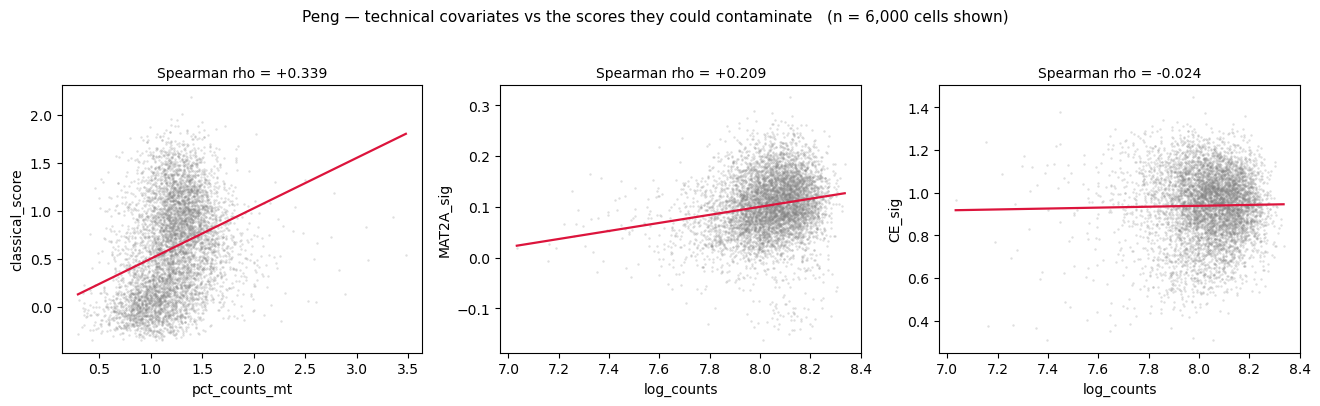

Both panels are non-flat, which is why every rho in this notebook is a PARTIAL
rho with both sides residualised on QC ranks. A flat panel would mean the
correction was unnecessary; these are not flat.


In [16]:
# ==========================================================================
# 9 · CONFOUND, DRAWN   ·   Fig. 2b/2c
# Same associations as the table above, as scatter + fit. Non-flat panels are the point:
# they are why every coefficient in this notebook is a partial rho with both sides
# residualised on QC ranks.
# ==========================================================================

# FIGURE — the confound, drawn. Same numbers as the table above.
fig_confound(mal.obs,
             [("pct_counts_mt", "classical_score"),
              ("log_counts", "MAT2A_sig"),
              ("log_counts", "CE_sig")],
             "Peng — technical covariates vs the scores they could contaminate",
             "peng")
print("Both panels are non-flat, which is why every rho in this notebook is a PARTIAL")
print("rho with both sides residualised on QC ranks. A flat panel would mean the")
print("correction was unnecessary; these are not flat.")


## 10 · What a standard (uncontrolled) analysis concludes

*Results → Distribution … (the uncontrolled baseline).* This is the **naive** within-patient
Spearman correlation, with **no** covariate correction — the analysis a standard pipeline would
run. It is reported so the effect of the controls in the next sections is visible as a change
from this baseline, not asserted.

In [17]:
# ==========================================================================
# 10 · NAIVE (UNCONTROLLED) ANALYSIS
# Within-patient Spearman with NO covariate correction -- the baseline a standard pipeline
# would report, shown so the effect of the controls is visible as a change from it.
# ==========================================================================

print("NAIVE within-patient Spearman vs classical score (NO controls)\n")
show([summarise(naive_spearman(mal.obs, t + "_sig"), t) for t in TARGETS])

NAIVE within-patient Spearman vs classical score (NO controls)

  signature                   n       neg    mean_rho         p
  VPS4A                      24     16/24     -0.0487    0.1074
  PRMT5                      24     10/24     +0.0207    0.2182
  MAT2A                      24      1/24     +0.3272    0.0000


## 11 · The proper method, and the negative controls  ·  **Fig. 3**

*Methods → Controls (Table 1); Results → Distribution of the Dependency Signatures.* The
QC-controlled within-patient partial Spearman correlation (both sides residualised) is computed
here, alongside the three negative controls of manuscript **Table 1**:

- **random gene-set null** (1,000 size-matched 96-gene sets drawn from the detected
  transcriptome) — is the effect above chance?
- **expression-matched null** (1,000 sets, each gene replaced by one of comparable mean
  expression, ±20 %) — a *harder* null: is the effect explained by expression level alone?
- **commonly-essential control** (the decisive one) — does generic essentiality deplete in
  classical cells as strongly?

Each stochastic step below takes its **own** generator seeded from `SEED`, rather than drawing
from a shared stream; the inline comment explains why this is not cosmetic.

In [18]:
# ==========================================================================
# 11 · QC-CONTROLLED ANALYSIS + NEGATIVE CONTROLS   (Table 1)   ·   Fig. 3
# res: partial Spearman vs classical score for the three targets + commonly-essential.
# null: the random-gene-set null (N_NULL size-matched draws). SD-from-random reported for
# each. See the inline note on why each stochastic step gets its OWN generator.
# ==========================================================================

# Each stochastic step below takes its OWN generator, seeded from SEED, rather than
# drawing from the shared `rng`. With a shared generator, which gene sets the null
# draws depends on how many random numbers every earlier cell happened to consume --
# so adding a figure, or a QC step that subsamples, silently reseeds the null. That is
# what moved common-essential from -3.5 to -2.5 to -1.9 SD across runs whose rhos were
# byte-identical. Separate streams make each null reproducible on its own terms.
def random_null(ad, present, n=N_NULL):
    _null_rng = np.random.default_rng(SEED)
    out = []
    for _ in range(n):
        g = list(_null_rng.choice(sorted(present), size=SIG_SIZE, replace=False))
        sc.tl.score_genes(ad, g, score_name="_r", use_raw=True)
        out.append(np.mean(list(partial_spearman(ad.obs, "_r").values())))
    return np.array(out)

def expression_matched_null(ad, template, n=N_NULL):
    _expr_rng = np.random.default_rng(SEED + 1)   # own stream -- see random_null
    # .raw.X directly -- to_adata() here copied the entire matrix for a column mean
    gm = pd.Series(np.asarray(ad.raw.X.mean(axis=0)).ravel(),
                   index=list(ad.raw.var_names))
    out = []
    for _ in range(n):
        picked = []
        for g in template:
            if g not in gm.index:
                continue
            cands = gm[(gm > gm[g] * 0.8) & (gm < gm[g] * 1.2)].index
            if len(cands):
                picked.append(str(_expr_rng.choice(cands)))
        sc.tl.score_genes(ad, list(set(picked)), score_name="_m", use_raw=True)
        out.append(np.mean(list(partial_spearman(ad.obs, "_m").values())))
    return np.array(out)

res = {t: partial_spearman(mal.obs, t + "_sig") for t in TARGETS}
res["common_essential"] = partial_spearman(mal.obs, "CE_sig")
null = random_null(mal, raw)

print("PARTIAL SPEARMAN vs classical score (QC-controlled, BOTH sides)\n")
show([summarise(v, k) for k, v in res.items()])
print("\nrandom null (n={}): mean {:+.4f} | sd {:.4f}\n".format(N_NULL, null.mean(), null.std()))
print("  {:<24}{:>16}".format("signature", "SD from random"))
for k, v in res.items():
    print("  {:<24}{:>+16.1f}".format(k, sd_from(summarise(v)["mean_rho"], null)))

PARTIAL SPEARMAN vs classical score (QC-controlled, BOTH sides)

  signature                   n       neg    mean_rho         p
  VPS4A                      24     15/24     -0.0365    0.1515
  PRMT5                      24      9/24     +0.0325    0.0691
  MAT2A                      24      2/24     +0.3094    0.0000
  common_essential           24     19/24     -0.1650    0.0007

random null (n=1000): mean +0.0186 | sd 0.0850

  signature                 SD from random
  VPS4A                               -0.6
  PRMT5                               +0.2
  MAT2A                               +3.4
  common_essential                    -2.2


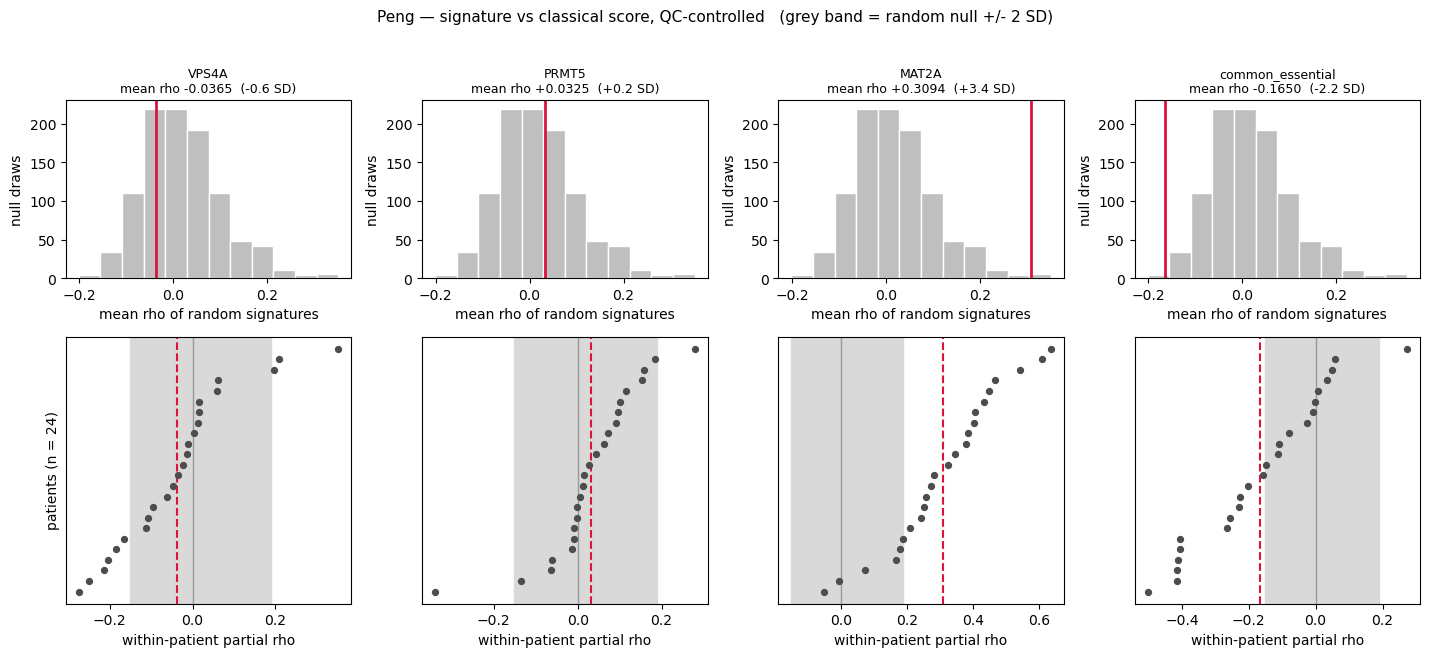

In [19]:
# ==========================================================================
# 11 · NULLS + PER-PATIENT FOREST (Peng)   ·   Fig. 3a/3c
# Pure consumer: reads res and null from the cell above and recomputes nothing.
# ==========================================================================

# FIGURE — null distributions and per-patient consistency (Peng).
# Reads the objects computed in the cell above; recomputes nothing.
fig_null_and_forest(res, null,
                    "Peng — signature vs classical score, QC-controlled",
                    "peng",
                    keys=TARGETS + ["common_essential"])


## 12 · The deciding test — head-to-head against generic essentiality  ·  **Fig. 4a**

*Results → Distribution … (specificity).* Paired, **within patient**, on the same cells: each
patient contributes its target coefficient and its commonly-essential coefficient, and the
**difference** (denoted **Δρ** in the manuscript) is tested with a Wilcoxon signed-rank test, so
any patient-level factor moving both signatures together cancels. A target that merely *matches*
generic essentiality **is** generic essentiality. The interpretation turns on **direction**:
VPS4A and PRMT5 sit above the depleted control only by staying flat, whereas MAT2A sits above it
by being **enriched** — the one direction a generic-essentiality confound cannot produce.

In [20]:
# ==========================================================================
# 12 · HEAD-TO-HEAD vs COMMONLY-ESSENTIAL (Peng)   ·   Fig. 4a
# Paired within patient (Delta-rho), Wilcoxon-tested. MAT2A beats the control in the
# OPPOSITE direction -- the one direction a generic-essentiality confound cannot fake.
# ==========================================================================

print("HEAD-TO-HEAD vs COMMON-ESSENTIAL (paired, within patient) -- PENG\n")
print("  {:<12}{:>5}{:>13}{:>20}{:>10}".format("target", "n", "mean diff", "more neg than CE", "p"))
for t in TARGETS:
    r = paired_vs(res[t], res["common_essential"])
    print("  {:<12}{:>5}{:>+13.4f}{:>20}{:>10.4f}".format(
        t, r["n"], r["mean_diff"], "{}/{}".format(r["n_more_neg"], r["n"]), r["p"]))
print("\n  MAT2A beats the control in the OPPOSITE direction, the one direction a")
print("  generic-essentiality confound cannot fake.")

HEAD-TO-HEAD vs COMMON-ESSENTIAL (paired, within patient) -- PENG

  target          n    mean diff    more neg than CE         p
  VPS4A          24      +0.1285                8/24    0.0491
  PRMT5          24      +0.1976                3/24    0.0000
  MAT2A          24      +0.4744                3/24    0.0000

  MAT2A beats the control in the OPPOSITE direction, the one direction a
  generic-essentiality confound cannot fake.


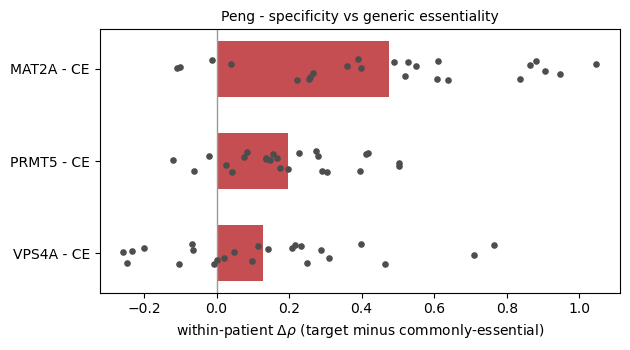

MAT2A is displaced above the control by being ENRICHED; VPS4A/PRMT5 sit above
it only because the control is depleted and they are flat.


In [21]:
# ===========================================================================
# FIGURE - HEAD-TO-HEAD vs COMMONLY-ESSENTIAL (Peng)   ·   manuscript Fig. 4a
# ===========================================================================
# Pure consumer of `res` from Section 12's cell: the within-patient difference
# (Delta-rho) between each target signature and the commonly-essential control.
# Bar = mean across patients; grey points = individual patients. Recomputes
# nothing stochastic.
if FIGURES:
    _keys = TARGETS
    _fig, _ax = plt.subplots(figsize=(6.4, 3.6))
    for _i, _t in enumerate(_keys):
        _pats = sorted(set(res[_t]) & set(res["common_essential"]))
        _d = np.array([res[_t][p] - res["common_essential"][p] for p in _pats])
        _ax.barh(_i, _d.mean(), color="#C44E52", height=0.6, zorder=2)
        _ax.scatter(_d, np.full(len(_d), _i) + np.random.default_rng(SEED).uniform(-0.12, 0.12, len(_d)),
                    s=14, color="0.3", zorder=3)
    _ax.axvline(0, color="0.6", lw=1)
    _ax.set_yticks(range(len(_keys)))
    _ax.set_yticklabels([t + " - CE" for t in _keys])
    _ax.set_xlabel(r"within-patient $\Delta\rho$ (target minus commonly-essential)")
    _ax.set_title("Peng - specificity vs generic essentiality", fontsize=10)
    plt.tight_layout()
    _show("peng_head_to_head")
    print("MAT2A is displaced above the control by being ENRICHED; VPS4A/PRMT5 sit above")
    print("it only because the control is depleted and they are flat.")


## 13 · Positive controls — proving the analysis has power  ·  **Fig. 4b**

*Methods/Results → Controls (sensitivity).* **The single most important defence of the negative
results.** Two signatures with *known* state-restriction — the proliferation signature against
the cell-cycle program, and the classical score against the classical program — are passed through
the same program-restriction pipeline (top tertile of program-high cells vs the remainder,
within patient). If the pipeline detects these easily but not the targets, then the VPS4A and
PRMT5 nulls are **real nulls**, not failures of sensitivity. The three target signatures are
shown on the same axis for scale.

In [22]:
# ==========================================================================
# 13 · POSITIVE CONTROLS (sensitivity)   ·   Fig. 4b
# program_restriction: within-patient difference between program-high cells (top tertile)
# and the rest. Proliferation->cell-cycle and classical->classical are KNOWN state-restricted
# and should register strongly; the targets, on the same axis, should not. This proves the
# pipeline can see state-restriction where it exists, so the VPS4A/PRMT5 nulls are real.
# ==========================================================================

def program_restriction(obs, score_col, program, min_cells=MIN_CELLS):
    col = "prog_" + program
    diffs = []
    for pat, g in obs.groupby("Patient", observed=True):
        if len(g) < min_cells:
            continue
        thr = g[col].quantile(0.66)
        hi, lo = g.loc[g[col] >= thr, score_col], g.loc[g[col] < thr, score_col]
        if len(hi) >= 10 and len(lo) >= 10:
            diffs.append(hi.mean() - lo.mean())
    d = np.array(diffs)
    return dict(n=len(d), mean_diff=float(d.mean()), p=float(wilcoxon(d)[1]))

print("POSITIVE CONTROLS (known state-restriction)\n")
print("  {:<18}{:<16}{:>5}{:>13}{:>10}".format("score", "program", "n", "mean diff", "p"))
for s_col, prog in [("prolif", "4_cellcycle"),
                    ("classical_score", CLASSICAL_PROG)]:
    r = program_restriction(mal.obs, s_col, prog)
    print("  {:<18}{:<16}{:>5}{:>+13.4f}{:>10.4f}".format(
        s_col, prog, r["n"], r["mean_diff"], r["p"]))
print("\n  The targets on the same axis, for scale:\n")
for t in TARGETS:
    r = program_restriction(mal.obs, t + "_sig", CLASSICAL_PROG)
    print("  {:<18}{:<16}{:>5}{:>+13.4f}{:>10.4f}".format(
        t + "_sig", CLASSICAL_PROG, r["n"], r["mean_diff"], r["p"]))
print("\n  -> the positive controls DWARF the targets. The pipeline sees ")
print("     state-restriction easily. It is simply not there for VPS4A or PRMT5.")

POSITIVE CONTROLS (known state-restriction)

  score             program             n    mean diff         p
  prolif            4_cellcycle        24      +0.2108    0.0000
  classical_score   8_classical        24      +0.3509    0.0000

  The targets on the same axis, for scale:

  VPS4A_sig         8_classical        24      +0.0047    0.2076
  PRMT5_sig         8_classical        24      -0.0082    0.0001
  MAT2A_sig         8_classical        24      +0.0292    0.0000

  -> the positive controls DWARF the targets. The pipeline sees 
     state-restriction easily. It is simply not there for VPS4A or PRMT5.


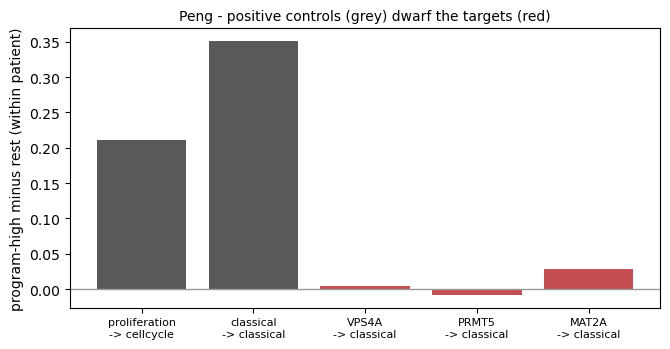

The pipeline detects known state-restriction easily; the targets barely move,
so the VPS4A/PRMT5 nulls reflect an absence of restriction, not a lack of power.


In [23]:
# ===========================================================================
# FIGURE - POSITIVE CONTROLS vs TARGETS on the program-restriction axis
#                (Peng)   ·   manuscript Fig. 4b
# ===========================================================================
# Recomputes via the same deterministic helper (program_restriction) used in the
# table above - no RNG, so identical to the printed values. Two known
# state-restricted signatures should tower over the three targets.
if FIGURES:
    _rows = [("proliferation", "prolif", "4_cellcycle"),
             ("classical", "classical_score", CLASSICAL_PROG),
             ("VPS4A", "VPS4A_sig", CLASSICAL_PROG),
             ("PRMT5", "PRMT5_sig", CLASSICAL_PROG),
             ("MAT2A", "MAT2A_sig", CLASSICAL_PROG)]
    _labels, _vals, _cols = [], [], []
    for _name, _sc, _prog in _rows:
        _r = program_restriction(mal.obs, _sc, _prog)
        _labels.append("{}\n-> {}".format(_name, _prog.split("_", 1)[-1]))
        _vals.append(_r["mean_diff"])
        _cols.append("0.35" if _name in ("proliferation", "classical") else "#C44E52")
    _fig, _ax = plt.subplots(figsize=(6.8, 3.6))
    _ax.bar(range(len(_labels)), _vals, color=_cols)
    _ax.axhline(0, color="0.6", lw=1)
    _ax.set_xticks(range(len(_labels)))
    _ax.set_xticklabels(_labels, fontsize=8)
    _ax.set_ylabel("program-high minus rest (within patient)")
    _ax.set_title("Peng - positive controls (grey) dwarf the targets (red)", fontsize=10)
    plt.tight_layout()
    _show("peng_positive_controls")
    print("The pipeline detects known state-restriction easily; the targets barely move,")
    print("so the VPS4A/PRMT5 nulls reflect an absence of restriction, not a lack of power.")


## 14 · MAT2A robustness tests (V1–V6)  ·  **Fig. 5**

*Methods → Robustness Tests (Table 2); Results → Validation of the MAT2A association.* Only the
MAT2A signature cleared the negative controls, so it alone is carried into the six robustness
tests. **Each pass criterion was fixed before the test was computed** — if any fails, MAT2A is
not a finding.

| test | challenge | passes if |
|---|---|---|
| **V1** circularity | overlap with Moffitt classical/basal genes | no classical-marker overlap drives it |
| **V2** proliferation | proliferation added to the QC covariates | the effect persists |
| **V3** scoring method | re-scored with a rank-based (AUCell-style) measure | the effect reproduces |
| **V4** aneuploidy | restricted to CNV-confirmed cells (Peng) | the effect persists |
| **V5** single-gene | each gene dropped in turn | no gene shifts the mean by > 30 % |
| **V6** compositional | compared to the expression-matched null | > 2 SD from that null |

In [24]:
# ==========================================================================
# 14 · ROBUSTNESS TESTS V1-V2 (Peng)   ·   Fig. 5
# V1 circularity: MAT2A signature genes vs the Moffitt classical/basal lists (a shared basal
# gene works AGAINST the enrichment, so it is conservative, not circular).
# V2 proliferation: adding proliferation to the QC covariates barely moves the coefficient,
# so the association is not a proliferation effect.
# ==========================================================================

mat = [g for g in signatures["MAT2A"] if g in raw]
full = summarise(res["MAT2A"])["mean_rho"]

print("V1. CIRCULARITY")
print("    MAT2A n Moffitt-CLASSICAL: {}  {}".format(
    len(set(mat) & set(MOFFITT_CLASSICAL)), sorted(set(mat) & set(MOFFITT_CLASSICAL))))
print("    MAT2A n Moffitt-BASAL:     {}  {}".format(
    len(set(mat) & set(MOFFITT_BASAL)), sorted(set(mat) & set(MOFFITT_BASAL))))
print("    NB: a BASAL marker in a classical-ENRICHED signature works AGAINST the")
print("        finding -- it makes the result conservative, not circular.\n")

print("V2. PROLIFERATION")
print("    classical vs prolif: {:+.3f} | MAT2A vs prolif: {:+.3f}".format(
    spearmanr(mal.obs["classical_score"], mal.obs["prolif"])[0],
    spearmanr(mal.obs["MAT2A_sig"], mal.obs["prolif"])[0]))
print("    (both nonzero => the mediation path classical <- prolif -> MAT2A is OPEN)\n")
show([summarise(res["MAT2A"], "MAT2A | QC only"),
      summarise(partial_spearman(mal.obs, "MAT2A_sig", covars=QC_COVARS + ["prolif"]),
                "MAT2A | QC + prolif")])

V1. CIRCULARITY
    MAT2A n Moffitt-CLASSICAL: 0  []
    MAT2A n Moffitt-BASAL:     1  ['CTSV']
    NB: a BASAL marker in a classical-ENRICHED signature works AGAINST the
        finding -- it makes the result conservative, not circular.

V2. PROLIFERATION
    classical vs prolif: -0.114 | MAT2A vs prolif: -0.183
    (both nonzero => the mediation path classical <- prolif -> MAT2A is OPEN)

  signature                   n       neg    mean_rho         p
  MAT2A | QC only            24      2/24     +0.3094    0.0000
  MAT2A | QC + prolif        24      2/24     +0.2965    0.0000


In [25]:
# ==========================================================================
# 14 · ROBUSTNESS TESTS V3-V4 (Peng)   ·   Fig. 5
# V3 scoring method: AUCell-style rank scoring reproduces the effect (no shared arithmetic
# with score_genes). V4 aneuploidy: restricting to CNV-confirmed cells (30-cell floor, since
# the restriction thins each patient) leaves MAT2A intact and VPS4A/PRMT5 null.
# ==========================================================================

print("V3. AUCELL -- orthogonal scoring\n")
mal.obs["MAT2A_auc"] = manual_aucell(mal, mat)
show([summarise(partial_spearman(mal.obs, "MAT2A_auc"), "MAT2A | AUCell")])
print("\n    AUCell vs score_genes agreement: {:+.3f}".format(
    spearmanr(mal.obs["MAT2A_auc"], mal.obs["MAT2A_sig"])[0]))

print("\n\nV4. CNV-CONFIRMED ANEUPLOID CELLS ONLY\n")
cnvobj = sc.read_h5ad(PENG_CNV)
ref = cnvobj.obs.loc[cnvobj.obs[MAL_COL].isin(["Immune cells", "Stromal cells"]), "cnv_score"]
aneu = set(cnvobj.obs.index[(cnvobj.obs[MAL_COL] == "Malignant cells") &
                            (cnvobj.obs["cnv_score"] > ref.quantile(0.95))])
sub = mal.obs[mal.obs.index.isin(aneu)].copy()
print("    CNV-confirmed aneuploid cells: {:,}\n".format(len(sub)))
show([summarise(partial_spearman(sub, t + "_sig", min_cells=30), t + " | aneuploid")
      for t in TARGETS])

V3. AUCELL -- orthogonal scoring

  signature                   n       neg    mean_rho         p
  MAT2A | AUCell             24      0/24     +0.2479    0.0000

    AUCell vs score_genes agreement: +0.693


V4. CNV-CONFIRMED ANEUPLOID CELLS ONLY

    CNV-confirmed aneuploid cells: 3,325

  signature                   n       neg    mean_rho         p
  VPS4A | aneuploid          19     12/19     -0.0582    0.1042
  PRMT5 | aneuploid          19      7/19     +0.0130    0.3321
  MAT2A | aneuploid          19      1/19     +0.2413    0.0000


In [26]:
# ==========================================================================
# 14 · ROBUSTNESS TESTS V5-V6 (Peng)   ·   Fig. 5
# V5 leave-one-out: no single gene shifts the mean coefficient by more than 30%.
# V6 compositional: MAT2A sits > 2 SD above the harder EXPRESSION-MATCHED null.
# ==========================================================================

print("V5. LEAVE-ONE-OUT\n")
deltas = []
for g in mat:
    sc.tl.score_genes(mal, [x for x in mat if x != g], score_name="_lo", use_raw=True)
    deltas.append((g, np.mean(list(partial_spearman(mal.obs, "_lo").values())) - full))
deltas.sort(key=lambda x: abs(x[1]), reverse=True)
print("    MAT2A full mean |rho = {:+.4f}\n".format(full))
for g, d in deltas[:5]:
    print("      drop {:<12} -> {:+.4f}   ({:.0f}% of effect)".format(
        g, d, abs(d) / abs(full) * 100))

print("\n\nV6. EXPRESSION-MATCHED NULL\n")
mnull = expression_matched_null(mal, mat)
print("    MAT2A                          : {:+.4f}".format(full))
print("    expression-matched nulls (n={}) : mean {:+.4f} | sd {:.4f}".format(
    N_NULL, mnull.mean(), mnull.std()))
print("\n    -> MAT2A is {:+.1f} SD from the EXPRESSION-MATCHED null".format(sd_from(full, mnull)))

V5. LEAVE-ONE-OUT

    MAT2A full mean |rho = +0.3094

      drop C19orf33     -> -0.0323   (10% of effect)
      drop CAPN8        -> -0.0298   (10% of effect)
      drop TPD52        -> -0.0209   (7% of effect)
      drop APOBEC3H     -> -0.0147   (5% of effect)
      drop TNFSF13      -> -0.0141   (5% of effect)


V6. EXPRESSION-MATCHED NULL

    MAT2A                          : +0.3094
    expression-matched nulls (n=1000) : mean +0.0785 | sd 0.0932

    -> MAT2A is +2.5 SD from the EXPRESSION-MATCHED null


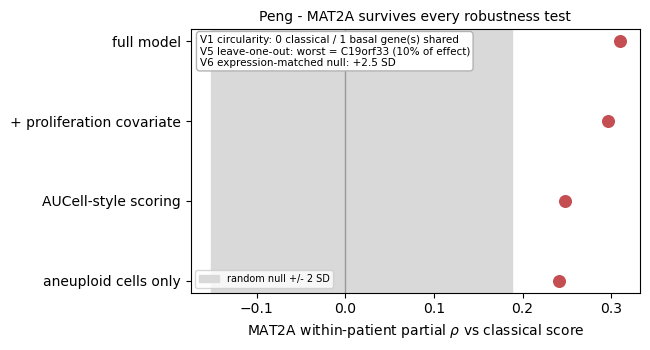

In [35]:
# ===========================================================================
# FIGURE - MAT2A ROBUSTNESS FOREST (Peng)   ·   manuscript Fig. 5
# ===========================================================================
# Consumes objects the robustness cells above already left in the namespace
# (full, sub, mnull, deltas, mat, null) and recomputes only the two cheap,
# deterministic partial-Spearman means for the +proliferation and AUCell rows
# (no RNG, no h5ad re-read). Each row is the MAT2A partial rho under one
# challenge, against the same +/-2 SD random-null band as Fig. 3.
if FIGURES:
    _full_rho  = full                                              # full model
    _prolif_rho = np.mean(list(partial_spearman(
        mal.obs, "MAT2A_sig", covars=QC_COVARS + ["prolif"]).values()))
    _auc_rho   = np.mean(list(partial_spearman(mal.obs, "MAT2A_auc").values()))
    _aneu_rho  = np.mean(list(partial_spearman(sub, "MAT2A_sig", min_cells=30).values()))
    _rows = [("full model", _full_rho),
             ("+ proliferation covariate", _prolif_rho),
             ("AUCell-style scoring", _auc_rho),
             ("aneuploid cells only", _aneu_rho)]
    _fig, _ax = plt.subplots(figsize=(6.6, 3.6))
    _y = np.arange(len(_rows))[::-1]
    _ax.axvspan(null.mean() - 2 * null.std(), null.mean() + 2 * null.std(),
                color="0.85", zorder=0, label="random null +/- 2 SD")
    _ax.axvline(0, color="0.6", lw=1)
    _ax.scatter([v for _, v in _rows], _y, s=70, color="#C44E52", zorder=3)
    _ax.set_yticks(_y)
    _ax.set_yticklabels([n for n, _ in _rows])
    _ax.set_xlabel(r"MAT2A within-patient partial $\rho$ vs classical score")
    _ax.set_title("Peng - MAT2A survives every robustness test", fontsize=10)
    # V1 / V5 / V6 are not coefficients on this axis -> annotate them
    _v1c = len(set(mat) & set(MOFFITT_CLASSICAL))
    _v1b = len(set(mat) & set(MOFFITT_BASAL))
    _worst_g, _worst_d = deltas[0]
    _v6_sd = sd_from(full, mnull)
    _txt = ("V1 circularity: {} classical / {} basal gene(s) shared\n"
            "V5 leave-one-out: worst = {} ({:.0f}% of effect)\n"
            "V6 expression-matched null: {:+.1f} SD").format(
        _v1c, _v1b, _worst_g, abs(_worst_d) / abs(full) * 100, _v6_sd)
    # All four points hug the RIGHT edge, so both annotations live on the LEFT
    # half now: the V1/V5/V6 box moves to the upper-left (va="top", y=0.98) and
    # the legend to the lower-left. This clears the entire right column, where the
    # bottom "aneuploid cells only" point was being hidden under the old lower-
    # right legend.
    _ax.legend(loc="lower left", fontsize=7)
    _ax.text(0.02, 0.98, _txt, transform=_ax.transAxes, fontsize=7.5, va="top",
             bbox=dict(boxstyle="round", fc="white", ec="0.7"))
    plt.tight_layout()
    _show("peng_mat2a_robustness")

## 15 · Independent replication — Steele  ·  **Fig. 3**

*Results → Distribution … (independent cohort).* The **entire** pipeline — QC-controlled partial
Spearman, negative controls, head-to-head against the commonly-essential control, and the V2/V3/V6
robustness tests — is re-run on the independent Steele cohort. Replication is only meaningful
because Steele was processed identically to Peng from raw counts (§4). This section also produces
the Steele half of manuscript **Fig. 3** and the two-cohort replication scatter.

In [28]:
# ==========================================================================
# 15 · INDEPENDENT REPLICATION -- STEELE   ·   Fig. 3b/3d
# The whole pipeline on the independent cohort: partial Spearman + nulls, head-to-head vs
# commonly-essential, and robustness tests V2/V3/V6. s_res / s_null mirror res / null.
# ==========================================================================

s_res = {t: partial_spearman(steele.obs, t + "_sig") for t in TARGETS}
s_res["common_essential"] = partial_spearman(steele.obs, "CE_sig")
s_null = random_null(steele, sraw)

print("STEELE -- partial Spearman vs classical score\n")
show([summarise(v, k) for k, v in s_res.items()])
print("\n  {:<24}{:>16}".format("signature", "SD from random"))
for k, v in s_res.items():
    print("  {:<24}{:>+16.1f}".format(k, sd_from(summarise(v)["mean_rho"], s_null)))

print("\n\nSTEELE -- head-to-head vs common-essential (paired)\n")
print("  {:<12}{:>5}{:>13}{:>20}{:>10}".format("target", "n", "mean diff", "more neg than CE", "p"))
for t in TARGETS:
    r = paired_vs(s_res[t], s_res["common_essential"])
    print("  {:<12}{:>5}{:>+13.4f}{:>20}{:>10.4f}".format(
        t, r["n"], r["mean_diff"], "{}/{}".format(r["n_more_neg"], r["n"]), r["p"]))

print("\n\nSTEELE -- MAT2A ROBUSTNESS ANALYSES (V2, V3, V6)\n")
s_mat = [g for g in signatures["MAT2A"] if g in sraw]
steele.obs["MAT2A_auc"] = manual_aucell(steele, s_mat)
show([summarise(s_res["MAT2A"], "MAT2A | QC only"),
      summarise(partial_spearman(steele.obs, "MAT2A_sig", covars=QC_COVARS + ["prolif"]),
                "MAT2A | QC + prolif"),
      summarise(partial_spearman(steele.obs, "MAT2A_auc"), "MAT2A | AUCell")])
s_mnull = expression_matched_null(steele, s_mat)
print("\n  MAT2A is {:+.1f} SD from the expression-matched null (Steele)".format(
    sd_from(summarise(s_res["MAT2A"])["mean_rho"], s_mnull)))

STEELE -- partial Spearman vs classical score

  signature                   n       neg    mean_rho         p
  VPS4A                      14      8/14     -0.0104    0.9515
  PRMT5                      14      5/14     +0.0134    0.6257
  MAT2A                      14      1/14     +0.3168    0.0002
  common_essential           14     11/14     -0.1666    0.0107

  signature                 SD from random
  VPS4A                               -0.2
  PRMT5                               +0.1
  MAT2A                               +4.0
  common_essential                    -2.3


STEELE -- head-to-head vs common-essential (paired)

  target          n    mean diff    more neg than CE         p
  VPS4A          14      +0.1562                5/14    0.1531
  PRMT5          14      +0.1800                3/14    0.0040
  MAT2A          14      +0.4834                1/14    0.0006


STEELE -- MAT2A ROBUSTNESS ANALYSES (V2, V3, V6)

  signature                   n       neg    mean_rho     

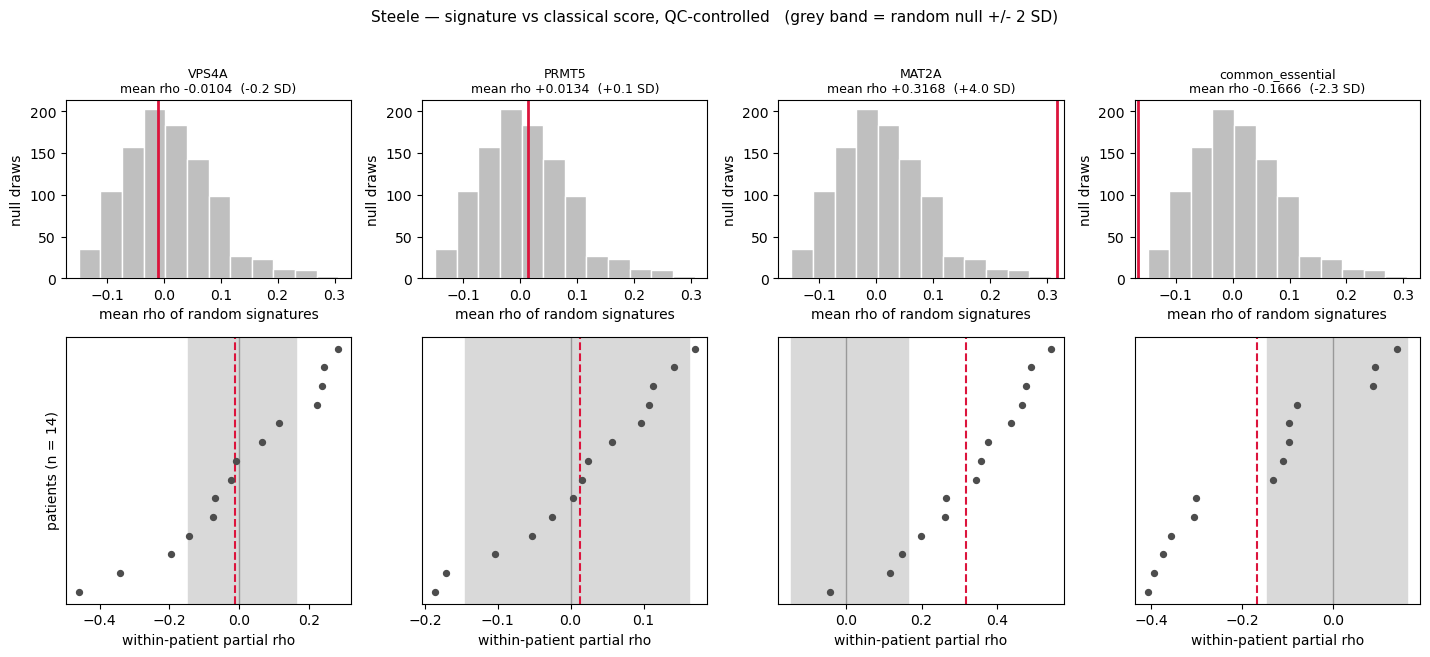

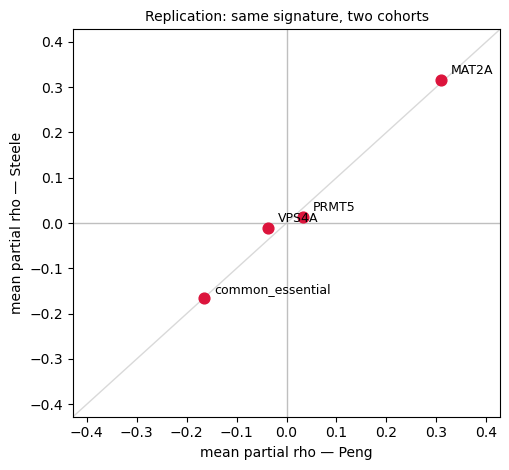

In [29]:
# ==========================================================================
# 15 · NULLS + FOREST (Steele) and TWO-COHORT REPLICATION SCATTER   ·   Fig. 3
# Mirrors the Peng figure so the cohorts can be compared by eye, then plots each signature's
# mean coefficient in Peng vs Steele (points on the diagonal = the cohorts agree).
# ==========================================================================

# FIGURE — null distributions and per-patient consistency (Steele).
# Mirrors the Peng figure exactly so the two cohorts can be compared by eye.
fig_null_and_forest(s_res, s_null,
                    "Steele — signature vs classical score, QC-controlled",
                    "steele",
                    keys=TARGETS + ["common_essential"])

# FIGURE — replication at a glance: each signature's rho in both cohorts.
if FIGURES:
    fig, ax = plt.subplots(figsize=(5.2, 4.8))
    keys = TARGETS + ["common_essential"]
    xs = [np.mean(list(res[k].values())) for k in keys]
    ys = [np.mean(list(s_res[k].values())) for k in keys]
    ax.axhline(0, color="0.75", lw=1)
    ax.axvline(0, color="0.75", lw=1)
    lim = max(map(abs, xs + ys)) * 1.35
    ax.plot([-lim, lim], [-lim, lim], color="0.85", lw=1, zorder=0)
    ax.scatter(xs, ys, s=60, color="crimson", zorder=3)
    for k, x, y in zip(keys, xs, ys):
        ax.annotate(k, (x, y), textcoords="offset points", xytext=(7, 4), fontsize=9)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_xlabel("mean partial rho — Peng")
    ax.set_ylabel("mean partial rho — Steele")
    ax.set_title("Replication: same signature, two cohorts", fontsize=10)
    plt.tight_layout()
    _show("peng_vs_steele_replication")


## 16 · Druggability — Pharos / TCRD Target Development Levels  ·  **Fig. 6**

*Methods/Results → Druggability.* The **Target Development Level (TDL)** grades a protein by how
much chemical matter exists against it:

| TDL | meaning |
|---|---|
| **Tclin** | approved drugs exist |
| **Tchem** | chemical probes / potent small molecules exist |
| **Tbio** | biology characterised, no chemical matter |
| **Tdark** | understudied |

Two descriptive questions (not hypothesis tests): (1) how tractable are the three targets and
their passenger / tumour-suppressor context? (2) does tractability differ across the malignant
**states** — the fraction of each program's top 30 genes that are Tclin or Tchem (**Fig. 6**)?
Queried **live** from the Pharos GraphQL API, with a cached fallback, so the notebook reports the
current value rather than one assumed from memory.

In [30]:
# ==========================================================================
# 16 · DRUGGABILITY -- THE THREE TARGETS (Pharos, live)
# Target Development Level for each target, its passenger gene, and the tumour suppressor
# deleted alongside it. A clean live pull refreshes the cache; if the API is down the cache
# is read and never overwritten with a failed pull.
# ==========================================================================

import requests, os, time

PHAROS  = "https://pharos-api.ncats.io/graphql"
QUERY   = "query($q: ITarget!){ target(q:$q){ sym tdl fam novelty } }"
TDL_CSV = os.path.join(DOWNLOADS, "target_tdl.csv")     # cache of a good run

def get_tdl(gene, retries=2):
    for _ in range(retries):
        try:
            r = requests.post(PHAROS, json={"query": QUERY, "variables": {"q": {"sym": gene}}},
                              timeout=20)
            r.raise_for_status()
            t = (r.json().get("data") or {}).get("target")
            if t:
                return {"gene": gene, "tdl": t.get("tdl"), "family": t.get("fam"),
                        "novelty": t.get("novelty")}
            return {"gene": gene, "tdl": "NOT_FOUND", "family": None, "novelty": None}
        except Exception:
            time.sleep(0.5)
    return None                                          # None = query failed (do NOT write)

CONTEXT = TARGETS + ["VPS4B", "MTAP", "CDKN2A", "SMAD4"]
rows    = [get_tdl(g) for g in CONTEXT]

if all(r is not None for r in rows):                     # clean live pull -> refresh cache
    tdl_targets = pd.DataFrame(rows)
    tdl_targets.to_csv(TDL_CSV, index=False)
    print("TARGET DEVELOPMENT LEVELS  (queried live from Pharos; cache refreshed)\n")
elif os.path.exists(TDL_CSV):                            # API down -> read cache, never overwrite
    tdl_targets = pd.read_csv(TDL_CSV).fillna("")
    print("TARGET DEVELOPMENT LEVELS  (Pharos unreachable; using cached values)\n")
else:
    raise RuntimeError("Pharos unreachable and no cache at {} -- run once on open internet.".format(TDL_CSV))

print(tdl_targets.to_string(index=False))
print("\n-> read against the main result: the one target whose vulnerability signature")
print("   is genuinely state-restricted is also the one with drugs in clinical trials.")

TARGET DEVELOPMENT LEVELS  (queried live from Pharos; cache refreshed)

  gene   tdl     family  novelty
 VPS4A  Tbio       None 0.015081
 PRMT5 Tchem Epigenetic 0.003955
 MAT2A Tchem     Enzyme 0.006677
 VPS4B Tchem       None 0.007887
  MTAP Tchem     Enzyme 0.004855
CDKN2A  Tbio     Enzyme 0.000141
 SMAD4  Tbio         TF 0.000471

-> read against the main result: the one target whose vulnerability signature
   is genuinely state-restricted is also the one with drugs in clinical trials.


In [31]:
# ==========================================================================
# 16 · DRUGGABILITY BY MALIGNANT STATE (Pharos, live)   ·   Fig. 6
# For each cNMF program, the fraction of its top 30 genes that are Tclin or Tchem. Descriptive,
# not a hypothesis test. Same live-pull-with-cache-fallback contract as the cell above.
# ==========================================================================

TOP_N    = 30
PROG_CSV = os.path.join(DOWNLOADS, "tractability_by_program.csv")   # cache of a good run

prog_top = {}
for i, name in enumerate(PROG_NAMES):
    prog_top[name] = [prog_genes[j] for j in np.argsort(programs[i])[::-1][:TOP_N]
                      if prog_genes[j] in raw]

def query_tractability():
    """Query Pharos for each program's top genes. Returns the table, or None if any
    gene query fails -- so a blocked run falls back to the cache instead of writing zeros."""
    order = ["Tclin", "Tchem", "Tbio", "Tdark"]
    all_genes = sorted(set(g for v in prog_top.values() for g in v))
    print("querying Pharos for {} program genes (a few minutes)...\n".format(len(all_genes)))
    cache = {}
    for i, g in enumerate(all_genes):
        rec = get_tdl(g)
        if rec is None:
            return None                                  # bail -> use the cache
        cache[g] = rec["tdl"]
        time.sleep(0.12)
        if (i + 1) % 50 == 0:
            print("  {}/{}".format(i + 1, len(all_genes)))
    rows = []
    for name, genes in prog_top.items():
        tdls = [cache.get(g, "NOT_FOUND") for g in genes]
        n = max(len(genes), 1)
        d = {"program": name, "n_genes": len(genes)}
        for k in order:
            d[k] = sum(1 for t in tdls if t == k)
        d["pct_tractable"] = round(100 * sum(1 for t in tdls if t in ("Tclin", "Tchem")) / n, 1)
        rows.append(d)
    return pd.DataFrame(rows)[["program", "n_genes", *order, "pct_tractable"]]

tract = query_tractability()

if tract is not None:                                    # clean live pull -> refresh cache
    tract.to_csv(PROG_CSV, index=False)
    print("\nTRACTABILITY BY MALIGNANT STATE  (queried live; cache refreshed)\n")
elif os.path.exists(PROG_CSV):                           # API down -> read cache, never overwrite
    tract = pd.read_csv(PROG_CSV).fillna("")
    print("\nTRACTABILITY BY MALIGNANT STATE  (Pharos unreachable; using cached values)\n")
else:
    raise RuntimeError("Pharos unreachable and no cache at {} -- run once on open internet.".format(PROG_CSV))

print(tract.sort_values("pct_tractable", ascending=False).to_string(index=False))

querying Pharos for 217 program genes (a few minutes)...

  50/217
  100/217
  150/217
  200/217

TRACTABILITY BY MALIGNANT STATE  (queried live; cache refreshed)

     program  n_genes  Tclin  Tchem  Tbio  Tdark  pct_tractable
      3_tuft       30      5      6    16      3           36.7
 4_cellcycle       30      1      8    21      0           30.0
    5_acinar       30      4      5    18      1           30.0
6_intestinal       30      1      5    19      1           20.0
    9_stress       30      0      6    22      0           20.0
    1_ductal       30      0      5    19      2           16.7
 8_classical       30      1      4    22      1           16.7
       2_CAF       30      1      3    25      1           13.3
     7_basal       30      1      3    23      1           13.3
 10_MAGE_CTA       30      0      3    23      1           10.0


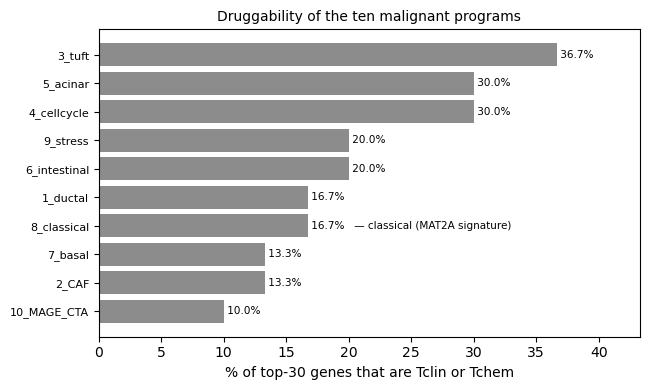

In [36]:
# ===========================================================================
# FIGURE - DRUGGABILITY BY MALIGNANT STATE   ·   manuscript Fig. 6
# ===========================================================================
# Pure consumer of `tract` from the cell above: the fraction of each program's
# top 30 genes that are Tclin or Tchem, ordered most to least druggable. The
# classical program (where the MAT2A signature concentrates) is tagged inline
# on its own value label (not colour-highlighted) - it ranks mid-pack, and a
# highlight would imply an extremity the data do not show.
if FIGURES:
    _t = tract.sort_values("pct_tractable", ascending=True)
    _progs = list(_t["program"])
    _pct = list(_t["pct_tractable"].astype(float))
    _fig, _ax = plt.subplots(figsize=(6.6, 4.0))
    _ax.barh(range(len(_progs)), _pct, color="0.55")
    _ax.set_yticks(range(len(_progs)))
    _ax.set_yticklabels(_progs, fontsize=8)
    # The classical program's callout is now INLINED onto its own value label.
    # Previously it was a separate arrow annotation whose text was parked to the
    # right of the bar tip, directly on top of the "16.7%" number; an inline tag
    # extends into the empty space past the bar and can never cover the value.
    _ci = _progs.index(CLASSICAL_PROG) if CLASSICAL_PROG in _progs else -1
    for _i, _v in enumerate(_pct):
        _lab = " {:.1f}%".format(_v)
        if _i == _ci:
            _lab += "   \u2014 classical (MAT2A signature)"
        _ax.text(_v, _i, _lab, va="center", fontsize=7.5)
    _ax.set_xlabel("% of top-30 genes that are Tclin or Tchem")
    _ax.set_title("Druggability of the ten malignant programs", fontsize=10)
    _ax.margins(x=0.18)
    plt.tight_layout()
    _show("druggability_by_program")

## 17 · Summary

*Results / Conclusion.* The three targets, both cohorts, side by side: coefficient, distance from
each cohort's own random-gene-set null (in SD), and Wilcoxon p. The final panel places all four
signatures on the null-distance axis for both cohorts at a glance.

In [33]:
# ==========================================================================
# 17 · SUMMARY TABLE
# The three targets in both cohorts: coefficient, SD from each cohort's own random null, and
# Wilcoxon p. Written to summary_three_targets.csv.
# ==========================================================================

print("RESULTS\n")
rows = []
for t in TARGETS:
    p, s = summarise(res[t]), summarise(s_res[t])
    rows.append({"target": t,
                 "Peng rho": round(p["mean_rho"], 4),
                 "Peng SD": round(sd_from(p["mean_rho"], null), 1),
                 "Peng p": round(p["p"], 4),
                 "Steele rho": round(s["mean_rho"], 4),
                 "Steele SD": round(sd_from(s["mean_rho"], s_null), 1),
                 "Steele p": round(s["p"], 4)})
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))
summary.to_csv(os.path.join(DOWNLOADS, "summary_three_targets.csv"), index=False)
print()
print("  VPS4A : not separated from a random gene list. Uniform.")
print("  PRMT5 : not separated from a random gene list. Uniform.")
print("  MAT2A : ENRICHED in classical cells in both cohorts, beating the")
print("          essentiality control in the opposite direction -- the one")
print("          direction a generic-essentiality confound cannot produce.")
print()
print("  Positive controls confirm the analysis detects genuine state-restriction")
print("  where it exists, so the VPS4A and PRMT5 nulls are real nulls.")
print()
print("  saved: summary_three_targets.csv")

RESULTS

target  Peng rho  Peng SD  Peng p  Steele rho  Steele SD  Steele p
 VPS4A   -0.0365     -0.6  0.1515     -0.0104       -0.2    0.9515
 PRMT5    0.0325      0.2  0.0691      0.0134        0.1    0.6257
 MAT2A    0.3094      3.4  0.0000      0.3168        4.0    0.0002

  VPS4A : not separated from a random gene list. Uniform.
  PRMT5 : not separated from a random gene list. Uniform.
  MAT2A : ENRICHED in classical cells in both cohorts, beating the
          essentiality control in the opposite direction -- the one
          direction a generic-essentiality confound cannot produce.

  Positive controls confirm the analysis detects genuine state-restriction
  where it exists, so the VPS4A and PRMT5 nulls are real nulls.

  saved: summary_three_targets.csv


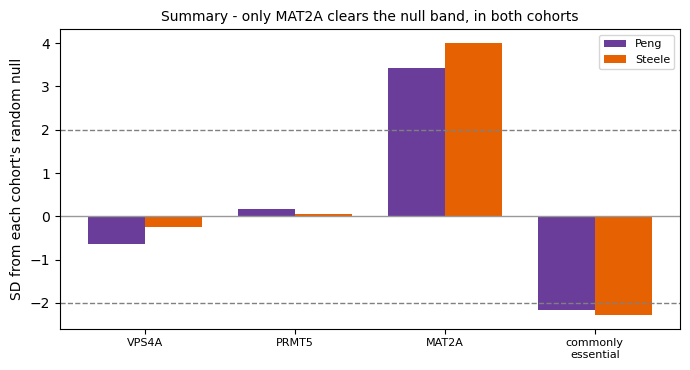

In [34]:
# ===========================================================================
# FIGURE - SUMMARY: distance from the random null, both cohorts
# ===========================================================================
# Pure consumer of res / s_res / null / s_null. All four signatures on the
# null-distance (SD) axis for both cohorts, with the +/-2 SD decision lines. One
# panel that carries the paper's whole result: MAT2A outside the band in both
# cohorts; VPS4A/PRMT5 inside; commonly-essential outside on the negative side.
if FIGURES:
    _keys = TARGETS + ["common_essential"]
    _peng_sd = [sd_from(summarise(res[k])["mean_rho"], null) for k in _keys]
    _stee_sd = [sd_from(summarise(s_res[k])["mean_rho"], s_null) for k in _keys]
    _x = np.arange(len(_keys)); _w = 0.38
    _fig, _ax = plt.subplots(figsize=(7.0, 3.8))
    _ax.bar(_x - _w / 2, _peng_sd, _w, color="#6A3D9A", label="Peng")
    _ax.bar(_x + _w / 2, _stee_sd, _w, color="#E66101", label="Steele")
    for _yv in (-2, 2):
        _ax.axhline(_yv, color="0.5", ls="--", lw=1)
    _ax.axhline(0, color="0.6", lw=1)
    _ax.set_xticks(_x)
    _ax.set_xticklabels([k.replace("common_essential", "commonly\nessential") for k in _keys],
                        fontsize=8)
    _ax.set_ylabel("SD from each cohort's random null")
    _ax.set_title("Summary - only MAT2A clears the null band, in both cohorts", fontsize=10)
    _ax.legend(fontsize=8)
    plt.tight_layout()
    _show("summary_sd_from_null")
